### Lib and Func

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

import warnings
warnings.filterwarnings("ignore")

In [2]:
MAIN_FOLDER_PATH = Path("mimic-iv-3.1")
HOSP_PATH = Path(f"{MAIN_FOLDER_PATH}/hosp")
ICU_PATH = Path(f"{MAIN_FOLDER_PATH}/icu")

In [3]:
def ShapeHeadMissing(df):
    print(f"Shape: {df.shape}")
    display(df.head())
    print(df.isna().sum())

def CompareDataAndKeys(df_small, df_big, cols):
    if df_small.set_index(cols).index.isin(df_big.set_index(cols).index).all():
        print(f"All data under {cols} in left df exists in right df")
    else:
        print("Missing information in description table")    

def VerifyUniqueKeys(df, cols):
    results_duplicated = df[cols].duplicated().any()
    if not results_duplicated:
        print(f"{cols} is unique to table")
    else:
        print(f"{cols} is not unique to table")

def VerifyCatConsistency(df, cols, sort_index_cols = None):
    pd.set_option("display.max_rows", None)
    for col in cols:
        if sort_index_cols and col in sort_index_cols:
            display(df[col].value_counts().sort_index())
        else:
            display(df[col].value_counts())            
        print()
        
    pd.reset_option("display.max_rows")

## <span style = "color:red"> Important notes from analysing all tables</span>
- For missing values with string columns, consider creating a value instead of leaving it NaN, like Unknown <span style = "color: red;">(check with Divya)</span>
    - Does not work for missing values in columns like double and date/timestamp
- For text consistency between string columns
    - Set all strings to Upper start and then lower for the rest, unless they are abbreviations within the string values
        - This can also fix data inconsistencies with some strings having capitalised and non-capitalised letters within the values
    - There are many data inconsistencies in the tables where some values in string columns have an extra `.` at the end. Remove all of them for standardisation
- Since timestamps are deidentified in the dataset, the dates itself should not be taken into consideration
    - Time can be taken into consideration (Divya)
- For Midhun
    - Null and Null Flags
        - Give reasoning to setting null and null flags, otherwise do not set it to null
    - Edit a column directly, reduce the need to create extra columns just to remove after editing
    - Pipeline for silver layer should not contain analysis if possible, if you want to do tests to check issues, do it in a separate file, not in the main file. The pipeline file is meant to run from Bronze -> Silver, not to debug/test and analyse data
        - Pharmacy disp_sched when checking errors for invalid time

### patients (Divya - Hosp) Done!
- subject_id is unique

In [4]:
patients_df = pd.read_csv(f"{HOSP_PATH}/patients.csv")

In [5]:
ShapeHeadMissing(patients_df)

Shape: (364627, 6)


,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10000032,F,52,2180,2014 - 2016,2180-09-09
1,10000048,F,23,2126,2008 - 2010,NaN
2,10000058,F,33,2168,2020 - 2022,NaN
3,10000068,F,19,2160,2008 - 2010,NaN
4,10000084,M,72,2160,2017 - 2019,2161-02-13


subject_id                0
gender                    0
anchor_age                0
anchor_year               0
anchor_year_group         0
dod                  326326
dtype: int64


In [6]:
VerifyUniqueKeys(patients_df, ["subject_id"])

['subject_id'] is unique to table


In [7]:
VerifyCatConsistency(patients_df,
                     ["gender"])

print("No inconsistencies")

gender
F    191984
M    172643
Name: count, dtype: int64


No inconsistencies


### admissions (Divya - Hosp) Done!

- `hadm_id` is unique
- <span style = "color:red;">Check with Divya:</span>
    - if we should standardise `UNKNOWN`, `UNABLE TO OBTAIN` and `PATIENT DECLINED TO ANSWER` for `race`
    - if we should fill in missing information for `admit_provider_id` (only 1 row, also the column is quite redundant)
        - [Hosp -> Admissions -> admit_provider_id](https://mimic.mit.edu/docs/iv/modules/hosp/admissions.html#admit_provider_id)
    - Note that we cannot filter data here because many other tables are very reliant on the `hadm_id`
    - Clarify new columns
        - los_hospital_days
            - Measures time between a patient's admission to the hospital and discharged time from the hospital
            - Looks good to me
        - ed_los_minutes
            - Measures time between registration and discharged time when the patient is in the emergency department
            - Looks good to me

In [8]:
admissions_df = pd.read_csv(f"{HOSP_PATH}/admissions.csv")

In [9]:
ShapeHeadMissing(admissions_df)

Shape: (546028, 16)


,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
0,10000032,22595853,2180-05-06 22:23:00,2180-05-07 17:15:00,NaN,URGENT,P49AFC,TRANSFER FROM HOSPITAL,HOME,Medicaid,English,WIDOWED,WHITE,2180-05-06 19:17:00,2180-05-06 23:30:00,0
1,10000032,22841357,2180-06-26 18:27:00,2180-06-27 18:49:00,NaN,EW EMER.,P784FA,EMERGENCY ROOM,HOME,Medicaid,English,WIDOWED,WHITE,2180-06-26 15:54:00,2180-06-26 21:31:00,0
2,10000032,25742920,2180-08-05 23:44:00,2180-08-07 17:50:00,NaN,EW EMER.,P19UTS,EMERGENCY ROOM,HOSPICE,Medicaid,English,WIDOWED,WHITE,2180-08-05 20:58:00,2180-08-06 01:44:00,0
3,10000032,29079034,2180-07-23 12:35:00,2180-07-25 17:55:00,NaN,EW EMER.,P06OTX,EMERGENCY ROOM,HOME,Medicaid,English,WIDOWED,WHITE,2180-07-23 05:54:00,2180-07-23 14:00:00,0
4,10000068,25022803,2160-03-03 23:16:00,2160-03-04 06:26:00,NaN,EU OBSERVATION,P39NWO,EMERGENCY ROOM,NaN,NaN,English,SINGLE,WHITE,2160-03-03 21:55:00,2160-03-04 06:26:00,0


subject_id                   0
hadm_id                      0
admittime                    0
dischtime                    0
deathtime               534238
admission_type               0
admit_provider_id            4
admission_location           1
discharge_location      149818
insurance                 9355
language                   775
marital_status           13619
race                         0
edregtime               166788
edouttime               166788
hospital_expire_flag         0
dtype: int64


In [10]:
VerifyUniqueKeys(admissions_df, ["hadm_id"])

['hadm_id'] is unique to table


In [11]:
VerifyCatConsistency(admissions_df,
                     ["admission_type", "admission_location", "discharge_location", "insurance", "language",
                      "marital_status", "race"])

admission_type
EW EMER.                       177459
EU OBSERVATION                 119456
OBSERVATION ADMIT               84437
URGENT                          54929
SURGICAL SAME DAY ADMISSION     42898
DIRECT OBSERVATION              24551
DIRECT EMER.                    21973
ELECTIVE                        13130
AMBULATORY OBSERVATION           7195
Name: count, dtype: int64

admission_location
EMERGENCY ROOM                            244179
PHYSICIAN REFERRAL                        163228
TRANSFER FROM HOSPITAL                     56227
WALK-IN/SELF REFERRAL                      42365
CLINIC REFERRAL                            12965
PROCEDURE SITE                              8518
TRANSFER FROM SKILLED NURSING FACILITY      6317
INTERNAL TRANSFER TO OR FROM PSYCH          5837
PACU                                        5734
INFORMATION NOT AVAILABLE                    402
AMBULATORY SURGERY TRANSFER                  255
Name: count, dtype: int64

discharge_location
HOME                            194204
HOME HEALTH CARE                 99305
SKILLED NURSING FACILITY         52657
REHAB                            13845
DIED                             11721
CHRONIC/LONG TERM ACUTE CARE      8125
HOSPICE                           5397
AGAINST ADVICE                    3393
PSYCH FACILITY                    2965
ACUTE HOSPITAL                    2334
OTHER FACILITY                    1592
ASSISTED LIVING                    622
HEALTHCARE FACILITY                 50
Name: count, dtype: int64

insurance
Medicare     244576
Private      173399
Medicaid     104229
Other         14006
No charge       463
Name: count, dtype: int64

language
English                   492316
Spanish                    18303
Russian                     8143
Chinese                     7598
Kabuverdianu                4801
Portuguese                  2938
Haitian                     2518
Other                       1392
Vietnamese                  1170
Italian                     1000
Modern Greek (1453-)         880
Arabic                       676
American Sign Language       522
Persian                      454
Polish                       417
Korean                       360
Thai                         288
Khmer                        264
Amharic                      254
Hindi                        191
French                       191
Somali                       160
Japanese                     158
Bengali                      152
Armenian                     107
Name: count, dtype: int64

marital_status
MARRIED     229134
SINGLE      206232
WIDOWED      56687
DIVORCED     40356
Name: count, dtype: int64

race
WHITE                                        336538
BLACK/AFRICAN AMERICAN                        75482
OTHER                                         19788
WHITE - OTHER EUROPEAN                        13972
UNKNOWN                                       13870
HISPANIC/LATINO - PUERTO RICAN                10903
HISPANIC OR LATINO                             8287
ASIAN                                          7809
ASIAN - CHINESE                                7644
WHITE - RUSSIAN                                6597
BLACK/CAPE VERDEAN                             6205
HISPANIC/LATINO - DOMINICAN                    6070
BLACK/CARIBBEAN ISLAND                         3875
BLACK/AFRICAN                                  3495
UNABLE TO OBTAIN                               3478
PATIENT DECLINED TO ANSWER                     2162
PORTUGUESE                                     2082
ASIAN - SOUTH EAST ASIAN                       1973
WHITE - EASTERN EUROPEAN                       1886
HISPANI

In [12]:
admissions_df.loc[admissions_df["admit_provider_id"].isna(), :]

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
5287,10106244,26713233,2147-05-09 10:34:00,2147-05-12 13:43:00,NaN,DIRECT EMER.,NaN,PHYSICIAN REFERRAL,HOME,Private,English,SINGLE,WHITE,NaN,NaN,0
201213,13700703,20448599,2172-09-25 01:01:00,2172-10-03 13:25:00,NaN,OBSERVATION ADMIT,NaN,EMERGENCY ROOM,HOME,Private,English,MARRIED,WHITE,2172-09-24 17:38:00,2172-09-25 03:07:00,0
296401,15443666,27961368,2168-12-30 23:30:00,2169-01-05 16:02:00,NaN,OBSERVATION ADMIT,NaN,EMERGENCY ROOM,HOME HEALTH CARE,Medicare,English,SINGLE,BLACK/AFRICAN AMERICAN,2168-12-30 11:19:00,2168-12-31 01:22:00,0
343701,16299919,26977065,2193-05-15 08:37:00,2193-05-17 16:03:00,NaN,OBSERVATION ADMIT,NaN,EMERGENCY ROOM,HOSPICE,Medicare,English,WIDOWED,BLACK/AFRICAN AMERICAN,2193-05-15 04:36:00,2193-05-15 14:27:00,0


In [13]:
admissions_df.loc[admissions_df["admission_location"].isna(), :]

,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
225404,14147342,22962235,2141-01-10 15:20:00,2141-03-01 13:03:00,NaN,URGENT,P71AZJ,NaN,HOME,Medicaid,NaN,NaN,WHITE - BRAZILIAN,NaN,NaN,0


In [14]:
admissions_df.loc[(admissions_df["admission_type"] == "URGENT"), "admission_location"].value_counts()

admission_location
TRANSFER FROM HOSPITAL                    25229
PHYSICIAN REFERRAL                        22271
INTERNAL TRANSFER TO OR FROM PSYCH         4129
TRANSFER FROM SKILLED NURSING FACILITY     1990
WALK-IN/SELF REFERRAL                       667
CLINIC REFERRAL                             205
PROCEDURE SITE                              180
EMERGENCY ROOM                              139
PACU                                         45
AMBULATORY SURGERY TRANSFER                  39
INFORMATION NOT AVAILABLE                    34
Name: count, dtype: int64

In [15]:
admissions_df.loc[(admissions_df["admission_type"] == "URGENT") & 
                    (admissions_df["discharge_location"] == "HOME"), "admission_location"].value_counts()

admission_location
PHYSICIAN REFERRAL                        20406
TRANSFER FROM HOSPITAL                     7853
INTERNAL TRANSFER TO OR FROM PSYCH         3174
WALK-IN/SELF REFERRAL                       408
CLINIC REFERRAL                             172
PROCEDURE SITE                              141
EMERGENCY ROOM                              119
TRANSFER FROM SKILLED NURSING FACILITY       49
PACU                                         35
INFORMATION NOT AVAILABLE                    24
AMBULATORY SURGERY TRANSFER                  15
Name: count, dtype: int64

In [16]:
admissions_df.loc[(admissions_df["edregtime"].isna()) & (admissions_df["edouttime"].isna()), :].shape

print("All missing edregtime will also result in missing edouttime")

All missing edregtime will also result in missing edouttime


In [17]:
CompareDataAndKeys(admissions_df, patients_df, ["subject_id"])

All data under ['subject_id'] in left df exists in right df


### transfers (Divya - hosp) Done!

- transfer_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp
- <span style = "color:red;">Check with Divya:</span>
    - This table has both the information of icustays - ICU and edstays - ED (We do not have access to ED table)
    - The transfers table has all the information of icustays - ICU, cannot confirm for edstays - ED since we do not have access to the table
    - Check whether this table is better and we can remove icustays, since the information already exists and more information on a patients transfer can be found here and avoid redundancy data
    - Note that we will not be analysing edstays - ED
    - [hosp -> transfers -> transfer_id](https://mimic.mit.edu/docs/iv/modules/hosp/transfers.html#subject_id-hadm_id-transfer_id)

In [18]:
transfers_df = pd.read_csv(f"{HOSP_PATH}/transfers.csv")

In [19]:
ShapeHeadMissing(transfers_df)

Shape: (2413581, 7)


,subject_id,hadm_id,transfer_id,eventtype,careunit,intime,outtime
0,10000032,22595853.0,33258284,ED,Emergency Department,2180-05-06 19:17:00,2180-05-06 23:30:00
1,10000032,22595853.0,35223874,admit,Transplant,2180-05-06 23:30:00,2180-05-07 17:21:27
2,10000032,22595853.0,36904543,discharge,UNKNOWN,2180-05-07 17:21:27,NaN
3,10000032,22841357.0,34100253,discharge,UNKNOWN,2180-06-27 18:49:12,NaN
4,10000032,22841357.0,34703856,admit,Transplant,2180-06-26 21:31:00,2180-06-27 18:49:12


subject_id          0
hadm_id        408977
transfer_id         0
eventtype           0
careunit            0
intime              0
outtime        546123
dtype: int64


In [20]:
VerifyUniqueKeys(transfers_df, ["transfer_id"])

['transfer_id'] is unique to table


In [21]:
transfers_df["eventtype"].value_counts()

eventtype
ED           784400
discharge    546024
admit        546010
transfer     537147
Name: count, dtype: int64

In [22]:
transfers_df.loc[transfers_df["hadm_id"].isna(), "eventtype"].value_counts()

eventtype
ED    408977
Name: count, dtype: int64

In [23]:
transfers_df.head(25)

,subject_id,hadm_id,transfer_id,eventtype,careunit,intime,outtime
0,10000032,22595853.0,33258284,ED,Emergency Department,2180-05-06 19:17:00,2180-05-06 23:30:00
1,10000032,22595853.0,35223874,admit,Transplant,2180-05-06 23:30:00,2180-05-07 17:21:27
2,10000032,22595853.0,36904543,discharge,UNKNOWN,2180-05-07 17:21:27,NaN
3,10000032,22841357.0,34100253,discharge,UNKNOWN,2180-06-27 18:49:12,NaN
4,10000032,22841357.0,34703856,admit,Transplant,2180-06-26 21:31:00,2180-06-27 18:49:12
5,10000032,22841357.0,38112554,ED,Emergency Department,2180-06-26 15:54:00,2180-06-26 21:31:00
6,10000032,25742920.0,35509340,admit,Transplant,2180-08-06 01:44:00,2180-08-07 17:50:44
7,10000032,25742920.0,35968195,ED,Emergency Department,2180-08-05 20:58:00,2180-08-06 01:44:00
8,10000032,25742920.0,38883756,discharge,UNKNOWN,2180-08-07 17:50:44,NaN
9,10000032,29079034.0,32952584,ED,Emergency Department,2180-07-22 16:24:00,2180-07-23 05:54:00


In [24]:
test_df = transfers_df.loc[transfers_df["subject_id"] == 10000084, :]
test_df

,subject_id,hadm_id,transfer_id,eventtype,careunit,intime,outtime
20,10000084,23052089.0,32326678,discharge,UNKNOWN,2160-11-25 14:52:20,NaN
21,10000084,23052089.0,34537425,admit,Medicine,2160-11-21 03:20:00,2160-11-25 14:52:20
22,10000084,23052089.0,35203156,ED,Emergency Department,2160-11-20 20:36:00,2160-11-21 03:20:00
23,10000084,29888819.0,30380331,discharge,UNKNOWN,2160-12-28 16:10:39,NaN
24,10000084,29888819.0,36954971,ED,Emergency Department,2160-12-27 18:32:00,2160-12-28 16:07:00
25,10000084,29888819.0,39560622,admit,Emergency Department Observation,2160-12-28 16:07:00,2160-12-28 16:10:39


In [25]:
test_df["intime"] = pd.to_datetime(test_df["intime"])
test_df["outtime"] = pd.to_datetime(test_df["outtime"])

In [26]:
test_df.sort_values("intime")

,subject_id,hadm_id,transfer_id,eventtype,careunit,intime,outtime
22,10000084,23052089.0,35203156,ED,Emergency Department,2160-11-20 20:36:00,2160-11-21 03:20:00
21,10000084,23052089.0,34537425,admit,Medicine,2160-11-21 03:20:00,2160-11-25 14:52:20
20,10000084,23052089.0,32326678,discharge,UNKNOWN,2160-11-25 14:52:20,NaT
24,10000084,29888819.0,36954971,ED,Emergency Department,2160-12-27 18:32:00,2160-12-28 16:07:00
25,10000084,29888819.0,39560622,admit,Emergency Department Observation,2160-12-28 16:07:00,2160-12-28 16:10:39
23,10000084,29888819.0,30380331,discharge,UNKNOWN,2160-12-28 16:10:39,NaT


### icustays (Divya - icu) Done!

- stay_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp
- first_careunit and last_careunit have relationship with transfers - hosp
    - [Hosp -> icustays -> careunit](https://mimic.mit.edu/docs/iv/modules/icu/icustays.html#first_careunit-last_careunit)
  - <span style = "color:red;">Check with Divya:</span>
    - Clarify new columns
        - los_icu_days_computed
            - Measures the time difference between intime and outtime, where both time refers to when the patient was transferred in and out of the ICU
            - Would this be preferred over the original los (length of stay)? Which is recorded as the duration based on the number of days (double datatype)

In [27]:
icustays_df = pd.read_csv(f"{ICU_PATH}/icustays.csv")

In [28]:
ShapeHeadMissing(icustays_df)

Shape: (94458, 8)


,subject_id,hadm_id,stay_id,first_careunit,last_careunit,intime,outtime,los
0,10000032,29079034,39553978,Medical Intensive Care Unit (MICU),Medical Intensive Care Unit (MICU),2180-07-23 14:00:00,2180-07-23 23:50:47,0.410266
1,10000690,25860671,37081114,Medical Intensive Care Unit (MICU),Medical Intensive Care Unit (MICU),2150-11-02 19:37:00,2150-11-06 17:03:17,3.893252
2,10000980,26913865,39765666,Medical Intensive Care Unit (MICU),Medical Intensive Care Unit (MICU),2189-06-27 08:42:00,2189-06-27 20:38:27,0.497535
3,10001217,24597018,37067082,Surgical Intensive Care Unit (SICU),Surgical Intensive Care Unit (SICU),2157-11-20 19:18:02,2157-11-21 22:08:00,1.118032
4,10001217,27703517,34592300,Surgical Intensive Care Unit (SICU),Surgical Intensive Care Unit (SICU),2157-12-19 15:42:24,2157-12-20 14:27:41,0.948113


subject_id         0
hadm_id            0
stay_id            0
first_careunit     0
last_careunit      0
intime             0
outtime           14
los               14
dtype: int64


In [29]:
VerifyCatConsistency(icustays_df,
                     ["first_careunit", "last_careunit"])

first_careunit
Medical Intensive Care Unit (MICU)                  20703
Medical/Surgical Intensive Care Unit (MICU/SICU)    15449
Cardiac Vascular Intensive Care Unit (CVICU)        14771
Surgical Intensive Care Unit (SICU)                 13009
Coronary Care Unit (CCU)                            10775
Trauma SICU (TSICU)                                 10474
Neuro Intermediate                                   5776
Neuro Surgical Intensive Care Unit (Neuro SICU)      1751
Neuro Stepdown                                       1421
Surgery/Vascular/Intermediate                         145
PACU                                                  122
Intensive Care Unit (ICU)                              33
Medicine                                               16
Surgery/Trauma                                         10
Medicine/Cardiology Intermediate                        1
Med/Surg                                                1
Neurology                                               1

last_careunit
Medical Intensive Care Unit (MICU)                  20703
Medical/Surgical Intensive Care Unit (MICU/SICU)    15449
Cardiac Vascular Intensive Care Unit (CVICU)        14771
Surgical Intensive Care Unit (SICU)                 13009
Coronary Care Unit (CCU)                            10775
Trauma SICU (TSICU)                                 10474
Neuro Intermediate                                   5776
Neuro Surgical Intensive Care Unit (Neuro SICU)      1751
Neuro Stepdown                                       1421
Surgery/Vascular/Intermediate                         145
PACU                                                  122
Intensive Care Unit (ICU)                              33
Medicine                                               16
Surgery/Trauma                                         10
Medicine/Cardiology Intermediate                        1
Med/Surg                                                1
Neurology                                               1


In [30]:
display(icustays_df.loc[icustays_df["first_careunit"] != icustays_df["last_careunit"], :])

print("first_careunit is always the same as last_careunit")

,subject_id,hadm_id,stay_id,first_careunit,last_careunit,intime,outtime,los


first_careunit is always the same as last_careunit


In [31]:
print(icustays_df.loc[(icustays_df["outtime"].isna()) & (icustays_df["los"].isna()), :].shape)

print("All missing outtime will also result in missing los (length of stay)")

(14, 8)
All missing outtime will also result in missing los (length of stay)


In [32]:
CompareDataAndKeys(icustays_df, patients_df, ["subject_id"])
CompareDataAndKeys(icustays_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


### d_items (Sean - icu) Done!

- itemid is unique
- unitname has inconsistent values with some having an extra '.' at the end, and should be removed
- label and abbreviation has lots of data inconsistencies
    - AT ( Antithrombin funct), AT (Antithrombin funct)
    - Code Status, Code Status.
    - Epinephrine, Epinephrine.

In [33]:
d_items_df = pd.read_csv(f"{ICU_PATH}/d_items.csv")

In [34]:
ShapeHeadMissing(d_items_df)

Shape: (4095, 9)


,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
0,220001,Problem List,Problem List,chartevents,General,NaN,Text,NaN,NaN
1,220003,ICU Admission date,ICU Admission date,datetimeevents,ADT,NaN,Date and time,NaN,NaN
2,220045,Heart Rate,HR,chartevents,Routine Vital Signs,bpm,Numeric,NaN,NaN
3,220046,Heart rate Alarm - High,HR Alarm - High,chartevents,Alarms,bpm,Numeric,NaN,NaN
4,220047,Heart Rate Alarm - Low,HR Alarm - Low,chartevents,Alarms,bpm,Numeric,NaN,NaN


itemid                0
label                 0
abbreviation          0
linksto               0
category              0
unitname           2972
param_type            0
lownormalvalue     4076
highnormalvalue    4073
dtype: int64


In [35]:
d_items_df.loc[d_items_df["unitname"].isna(), :]

,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
0,220001,Problem List,Problem List,chartevents,General,NaN,Text,NaN,NaN
1,220003,ICU Admission date,ICU Admission date,datetimeevents,ADT,NaN,Date and time,NaN,NaN
5,220048,Heart Rhythm,Heart Rhythm,chartevents,Routine Vital Signs,NaN,Text,NaN,NaN
21,220120,Intra Aortic Ballon Pump Setting,Intra Aortic Ballon Pump Setting,chartevents,IABP,NaN,Text,NaN,NaN
35,220274,PH (Venous),PH (Venous),chartevents,Labs,NaN,Numeric,NaN,NaN
...,...,...,...,...,...,...,...,...,...
4090,230172,Patient Reversed,Patient Reversed,procedureevents,3-Significant Events,NaN,Processes,NaN,NaN
4091,230173,Patient - Fast Track Protocol,Patient - Fast Track Protocol,procedureevents,3-Significant Events,NaN,Processes,NaN,NaN
4092,230174,Nerve block in OR,Nerve block in OR,procedureevents,3-Significant Events,NaN,Processes,NaN,NaN
4093,230176,IUC Stabilization Device,IUC Stabilization Device,chartevents,GI/GU,NaN,Checkbox,NaN,NaN


In [36]:
d_items_df.loc[-d_items_df["lownormalvalue"].isna(), :]

,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
6,220050,Arterial Blood Pressure systolic,ABPs,chartevents,Routine Vital Signs,mmHg,Numeric,90.0,140.0
7,220051,Arterial Blood Pressure diastolic,ABPd,chartevents,Routine Vital Signs,mmHg,Numeric,60.0,90.0
11,220059,Pulmonary Artery Pressure systolic,PAPs,chartevents,Hemodynamics,mmHg,Numeric,15.0,25.0
12,220060,Pulmonary Artery Pressure diastolic,PAPd,chartevents,Hemodynamics,mmHg,Numeric,8.0,15.0
13,220061,Pulmonary Artery Pressure mean,PAPm,chartevents,Hemodynamics,mmHg,Numeric,10.0,20.0
16,220069,Left Artrial Pressure,LAP,chartevents,Hemodynamics,mmHg,Numeric,6.0,12.0
20,220088,Cardiac Output (thermodilution),CO (thermodilution),chartevents,Hemodynamics,L/min,Numeric,4.0,8.0
348,223772,SvO2,SvO2,chartevents,Hemodynamics,%,Numeric,60.0,80.0
795,224684,Tidal Volume (set),Tidal Volume (set),chartevents,Respiratory,mL,Numeric,299.0,750.0
796,224685,Tidal Volume (observed),Tidal Volume (observed),chartevents,Respiratory,mL,Numeric,299.0,750.0


In [37]:
VerifyUniqueKeys(d_items_df, ["itemid"])

['itemid'] is unique to table


In [38]:
VerifyCatConsistency(d_items_df,
                     ["linksto", "category", "unitname", "param_type"],
                     ["category", "unitname", "param_type"])

linksto
chartevents         3055
inputevents          476
datetimeevents       190
procedureevents      173
ingredientevents     124
outputevents          77
Name: count, dtype: int64

category
1-Intubation/Extubation                 6
2-Ventilation                           2
3-Significant Events                   26
4-Procedures                           40
5-Imaging                              18
6-Cultures                             11
7-Communication                         8
ADT                                     7
Access Lines - Invasive               372
Access Lines - Peripheral              75
Adm History/FHPA                       49
Alarms                                 38
Antibiotics                            55
ApacheII Parameters                     3
ApacheIV Parameters                     2
Arterial Line Insertion                43
Block Charting Note                     6
Blood Products/Colloids                27
Bronchoscopy                           61
CVL Insertion                          53
Cardiovascular                         36
Cardiovascular (Pacer Data)            25
Cardiovascular (Pulses)                18
Care Plans               

unitname
%                       40
/min                     1
Degree                   1
Inch                     1
International Units      1
Kcal                     2
L/min                   30
L/min/m2                 3
Liters                   2
RPM                      6
Watts                    1
bpm                     13
cm                      73
cmH2O                   21
cmH2O/L/seconds          4
dose                    67
dynes*sec/cm5            3
dynes*sec/cm5/m2         1
dynes.sec.cm-5/m2        2
g/dl                     1
g/kg                     1
grams                   11
hour                     1
insp/min                 9
kJ                       1
kcal/day                 1
kcal/kg                  1
kg                       3
lbs                      4
mA                       6
mEq                      7
mEq.                     1
mL                     411
mL SC                    3
mL/beat                  2
mL/m2                    3
mL/min/m2          

param_type
Checkbox             372
Date and time        191
Ingredient           125
Numeric              804
Numeric with tag      43
Processes            173
Solution             476
Text                1911
Name: count, dtype: int64

In [39]:
pd.set_option("display.max_rows", None)
display(d_items_df["label"].value_counts().sort_index())
pd.reset_option("display.max_rows")

label
% Minute Volume                                                                                    1
14 G Infiltration Scale                                                                            1
14 G Phlebitis Scale                                                                               1
14 Gauge                                                                                           1
14 Gauge Cap Change                                                                                1
14 Gauge Dressing Change                                                                           1
14 Gauge Dressing Occlusive                                                                        1
14 Gauge Insertion Date                                                                            1
14 Gauge Reason Discontinued                                                                       1
14 Gauge Site Appear                                                                 

### d_icd_procedures (Hansen - hosp) Done!

- icu_code and icu_version are unique

In [40]:
d_icd_procedures_df = pd.read_csv(f"{HOSP_PATH}/d_icd_procedures.csv")

In [41]:
ShapeHeadMissing(d_icd_procedures_df)

Shape: (86423, 3)


,icd_code,icd_version,long_title
0,0001,9,Therapeutic ultrasound of vessels of head and neck
1,0002,9,Therapeutic ultrasound of heart
2,0003,9,Therapeutic ultrasound of peripheral vascular vessels
3,0009,9,Other therapeutic ultrasound
4,001,10,"Central Nervous System and Cranial Nerves, Bypass"


icd_code       0
icd_version    0
long_title     0
dtype: int64


In [42]:
VerifyUniqueKeys(d_icd_procedures_df, ["icd_code", "icd_version"])

['icd_code', 'icd_version'] is unique to table


### procedures_icd (Hansen - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - d_icd_procedures - Hosp
- <span style = "color:red;">Check with Hansen:</span>
    - Can consider renaming procedures_icd to icd_procedures since only d_icd_procedures is linked to procedures_icd

In [43]:
procedures_icd_df = pd.read_csv(f"{HOSP_PATH}/procedures_icd.csv")

In [44]:
ShapeHeadMissing(procedures_icd_df)

Shape: (859655, 6)


,subject_id,hadm_id,seq_num,chartdate,icd_code,icd_version
0,10000032,22595853,1,2180-05-07,5491,9
1,10000032,22841357,1,2180-06-27,5491,9
2,10000032,25742920,1,2180-08-06,5491,9
3,10000068,25022803,1,2160-03-03,8938,9
4,10000117,27988844,1,2183-09-19,0QS734Z,10


subject_id     0
hadm_id        0
seq_num        0
chartdate      0
icd_code       0
icd_version    0
dtype: int64


In [45]:
CompareDataAndKeys(procedures_icd_df, patients_df, ["subject_id"])
CompareDataAndKeys(procedures_icd_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(procedures_icd_df, d_icd_procedures_df, ["icd_code", "icd_version"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['icd_code', 'icd_version'] in left df exists in right df


### procedureevents (Hansen - icu) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - cargiver - icu (missing)
    - d_items - icu
- location has inconsistent values with some having an extra '.' at the end. To be removed

In [46]:
procedureevents_df = pd.read_csv(f"{ICU_PATH}/procedureevents.csv")

In [47]:
ShapeHeadMissing(procedureevents_df)

Shape: (808706, 22)


,subject_id,hadm_id,stay_id,caregiver_id,starttime,endtime,storetime,itemid,value,valueuom,location,locationcategory,orderid,linkorderid,ordercategoryname,ordercategorydescription,patientweight,isopenbag,continueinnextdept,statusdescription,originalamount,originalrate
0,10000032,29079034,39553978,18704.0,2180-07-23 14:43:00,2180-07-23 14:44:00,2180-07-23 14:43:00,225966,1.0,NaN,NaN,NaN,3050203,3050203,Procedures,Task,39.4,0,0,FinishedRunning,1.0,0
1,10000032,29079034,39553978,NaN,2180-07-23 14:24:00,2180-07-23 23:50:00,2180-07-23 23:50:49.983,224275,566.0,min,NaN,NaN,769190,769190,Peripheral Lines,ContinuousProcess,39.4,1,0,FinishedRunning,566.0,1
2,10000032,29079034,39553978,NaN,2180-07-23 14:24:00,2180-07-23 23:50:00,2180-07-23 23:50:49.983,224277,566.0,min,NaN,NaN,2668055,2668055,Peripheral Lines,ContinuousProcess,39.4,1,0,FinishedRunning,566.0,1
3,10000690,25860671,37081114,17393.0,2150-11-02 20:00:00,2150-11-03 13:00:00,2150-11-03 14:50:00,224275,1020.0,min,RL Ant Forearm Medial,Peripheral - old,301419,301419,Peripheral Lines,ContinuousProcess,55.3,1,0,FinishedRunning,1020.0,1
4,10000690,25860671,37081114,17393.0,2150-11-02 20:38:00,2150-11-03 11:59:00,2150-11-03 12:34:00,224277,921.0,min,L Antecube,Peripheral - old,5207974,5207974,Peripheral Lines,ContinuousProcess,55.3,1,0,FinishedRunning,921.0,1


subject_id                       0
hadm_id                          0
stay_id                          0
caregiver_id                157542
starttime                        0
endtime                          0
storetime                        0
itemid                           0
value                            0
valueuom                    412401
location                    631364
locationcategory            631364
orderid                          0
linkorderid                      0
ordercategoryname                0
ordercategorydescription         0
patientweight                    0
isopenbag                        0
continueinnextdept               0
statusdescription                0
originalamount                   0
originalrate                     0
dtype: int64


In [48]:
print(procedureevents_df.loc[procedureevents_df["valueuom"].isna(), "value"].value_counts())
print(procedureevents_df.loc[procedureevents_df["value"] == 1.0, "valueuom"].value_counts())

print("With the above, missing valueuom have a value of 1.0, while values with 1.0 can have filled data in valueuom")
print("Can accept the missing values")

value
1.0    412401
Name: count, dtype: int64
valueuom
day     267
min     133
hour     56
Name: count, dtype: int64
With the above, missing valueuom have a value of 1.0, while values with 1.0 can have filled data in valueuom
Can accept the missing values


In [49]:
print(procedureevents_df.loc[(procedureevents_df["location"].isna()) & (procedureevents_df["locationcategory"].isna()), :].shape)

print("With the above missing values, this means that missing locations would also mean a missing locationcategory. Therefore, no inconsistencies and can accept the missing values")

(631364, 22)
With the above missing values, this means that missing locations would also mean a missing locationcategory. Therefore, no inconsistencies and can accept the missing values


In [50]:
VerifyCatConsistency(procedureevents_df,
                     ["location", "locationcategory", "ordercategoryname", "ordercategorydescription", "statusdescription"])

location
Right IJ                    19578
Right Radial                15319
Right Antecubital           13649
Left Antecubital            12690
Left Radial                 12517
Left Cephalic Lower Arm      9809
Right Metacarpal             8907
Left Metacarpal              8765
Right Cephalic Lower Arm     8565
Left Basilic Lower Arm       7177
Right Basilic Lower Arm      7080
Urethral                     5227
Right Femoral.               3492
Right Accessory Cephalic     2591
Left IJ                      2523
Left Accessory Cephalic      2281
Right Femoral                2180
Left Digital                 1991
Right Digital                1820
Left Femoral.                1787
R Antecube                   1431
L Antecube                   1333
Right Accessory Basilic      1291
Left Subclavian              1276
Right Subclavian             1203
L Hand                       1145
Left Accessory Basilic       1086
Left above Antecubital       1067
R Hand                       1058
Left 

locationcategory
Peripheral             93827
Invasive Venous        32839
Invasive Arterial      32540
Peripheral - old        9472
Catheter, GU            5255
Dialysis                1909
ICP Line                 803
Intraosseous             444
Peritoneal Dialysis      253
Name: count, dtype: int64

ordercategoryname
Peripheral Lines         208943
Procedures               179248
Imaging                  131953
Invasive Lines           113220
Ventilation               38717
Communication             36027
Intubation/Extubation     35260
Significant Events        29597
Tubes                     22077
Continuous Procedures      6704
Dialysis                   5399
Peritoneal Dialysis         792
17 - Inhaled Meds           453
CRRT Filter Change          316
Name: count, dtype: int64

ordercategorydescription
Task                 412401
ContinuousProcess    396305
Name: count, dtype: int64

statusdescription
FinishedRunning    795893
Stopped             12232
Paused                581
Name: count, dtype: int64

In [51]:
pd.set_option("display.max_rows", None)
display(procedureevents_df.groupby("locationcategory")["location"].value_counts())
pd.reset_option("display.max_rows")

locationcategory     location                
Catheter, GU         Urethral                     5227
                     Other                          23
                     Ostomy                          5
Dialysis             Right IJ.                     728
                     Left IJ.                      436
                     R Femoral                     245
                     L Femoral                     206
                     R Subclavian                  179
                     L Subclavian                  107
                     Right EJ                        5
                     Left EJ                         3
ICP Line             R Ventricular                 457
                     L Ventricular                 161
                     Lumbar                        138
                     R Intraparenchymal             33
                     L Intraparenchymal             14
Intraosseous         Left Proximal Tibia           200
                   

Just edit location to remove the extra `.`

In [52]:
pd.set_option("display.max_rows", None)
display(procedureevents_df["location"].value_counts())
pd.reset_option("display.max_rows")

location
Right IJ                    19578
Right Radial                15319
Right Antecubital           13649
Left Antecubital            12690
Left Radial                 12517
Left Cephalic Lower Arm      9809
Right Metacarpal             8907
Left Metacarpal              8765
Right Cephalic Lower Arm     8565
Left Basilic Lower Arm       7177
Right Basilic Lower Arm      7080
Urethral                     5227
Right Femoral.               3492
Right Accessory Cephalic     2591
Left IJ                      2523
Left Accessory Cephalic      2281
Right Femoral                2180
Left Digital                 1991
Right Digital                1820
Left Femoral.                1787
R Antecube                   1431
L Antecube                   1333
Right Accessory Basilic      1291
Left Subclavian              1276
Right Subclavian             1203
L Hand                       1145
Left Accessory Basilic       1086
Left above Antecubital       1067
R Hand                       1058
Left 

In [53]:
# # Commented out code to not fix issue while analysing

# procedureevents_df["location"] = procedureevents_df["location"].str.rstrip(".")

# pd.set_option("display.max_rows", None)
# display(procedureevents_df["location"].value_counts())
# pd.reset_option("display.max_rows")

In [54]:
CompareDataAndKeys(procedureevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(procedureevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(procedureevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(procedureevents_df, d_items_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


### ingredientevents (Hansen - icu) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - d_items - icu

In [55]:
ingredientevents_df = pd.read_csv(f"{ICU_PATH}/ingredientevents.csv")

In [56]:
ShapeHeadMissing(ingredientevents_df)

Shape: (14253480, 17)


,subject_id,hadm_id,stay_id,caregiver_id,starttime,endtime,storetime,itemid,amount,amountuom,rate,rateuom,orderid,linkorderid,statusdescription,originalamount,originalrate
0,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:01:00,2180-07-23 18:56:00,220490,200.000000,mL,NaN,NaN,3782233,3782233,FinishedRunning,0,200.0
1,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:01:00,2180-07-23 18:56:00,227075,200.000000,mL,NaN,NaN,3782233,3782233,FinishedRunning,0,200.0
2,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:30:00,2180-07-23 17:02:00,220490,49.999999,mL,100.0,mL/hour,9796595,9796595,FinishedRunning,0,50.0
3,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:30:00,2180-07-23 17:02:00,226509,49.999999,mL,100.0,mL/hour,9796595,9796595,FinishedRunning,0,50.0
4,10000032,29079034,39553978,18704,2180-07-23 17:33:00,2180-07-23 18:03:00,2180-07-23 18:16:00,220490,49.999999,mL,100.0,mL/hour,6689854,6689854,FinishedRunning,0,50.0


subject_id                 0
hadm_id                    0
stay_id                    0
caregiver_id               0
starttime                  0
endtime                    0
storetime                  0
itemid                     0
amount                     0
amountuom                  0
rate                 5171995
rateuom              5171995
orderid                    0
linkorderid                0
statusdescription          0
originalamount             0
originalrate               0
dtype: int64


In [57]:
print(ingredientevents_df.loc[(ingredientevents_df["rate"].isna()) & (ingredientevents_df["rateuom"].isna()), :].shape)

print("All missing data in rate is also missing in rateuom. No issues.")

(5171995, 17)
All missing data in rate is also missing in rateuom. No issues.


In [58]:
ingredientevents_df.loc[ingredientevents_df["orderid"] != ingredientevents_df["linkorderid"], :].head()

,subject_id,hadm_id,stay_id,caregiver_id,starttime,endtime,storetime,itemid,amount,amountuom,rate,rateuom,orderid,linkorderid,statusdescription,originalamount,originalrate
22,10000690,25860671,37081114,17393,2150-11-02 22:45:00,2150-11-02 23:36:00,2150-11-02 23:12:00,220490,5.875468,mL,6.912315,mL/hour,8873311,8033236,ChangeDose/Rate,0,227.184738
23,10000690,25860671,37081114,17393,2150-11-02 22:45:00,2150-11-02 23:36:00,2150-11-02 23:12:00,227074,5.875468,mL,6.912315,mL/hour,8873311,8033236,ChangeDose/Rate,0,227.184738
24,10000690,25860671,37081114,17393,2150-11-02 23:36:00,2150-11-03 00:35:00,2150-11-03 00:42:00,220490,5.438254,mL,5.530427,mL/hour,772491,8033236,ChangeDose/Rate,0,221.309265
25,10000690,25860671,37081114,17393,2150-11-02 23:36:00,2150-11-03 00:35:00,2150-11-03 00:42:00,227074,5.438254,mL,5.530427,mL/hour,772491,8033236,ChangeDose/Rate,0,221.309265
26,10000690,25860671,37081114,17393,2150-11-03 00:35:00,2150-11-03 01:07:00,2150-11-03 00:43:00,220490,2.211935,mL,4.147378,mL/hour,5439562,8033236,ChangeDose/Rate,0,215.871017


In [59]:
VerifyCatConsistency(ingredientevents_df, 
                     ["amountuom", "rateuom", "statusdescription"],
                     ["rateuom", "statusdescription"])

amountuom
mL       11818655
Kcal      2038268
grams      232045
mg         148179
kJ          16333
Name: count, dtype: int64

rateuom
grams/hour      47298
mL/hour       8621899
mL/kg/hour        109
mL/kg/min          14
mL/min           1305
mcg/hour          182
mcg/kg/min     402985
mcg/min            54
mg/hour          7531
mg/min             18
units/hour         36
µL/kg/min          54
Name: count, dtype: int64

statusdescription
Bolus                 6064
ChangeDose/Rate    3832661
FinishedRunning    8947825
Paused              609437
Reported                 2
Stopped             857491
Name: count, dtype: int64

In [60]:
CompareDataAndKeys(ingredientevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(ingredientevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(ingredientevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(ingredientevents_df, d_items_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


### inputevents (Hansen - icu) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - d_items - icu
    - caregiver - icu
- Data issues in
    - amountuom
        - mEq, mEq.
    - ordercomponenttypedescription
        - Additives Ampoule has an extra whitespaces within the data. Have to be manually edited

In [61]:
inputevents_df = pd.read_csv(f"{ICU_PATH}/inputevents.csv")

In [62]:
ShapeHeadMissing(inputevents_df)

Shape: (10953713, 26)


,subject_id,hadm_id,stay_id,caregiver_id,starttime,endtime,storetime,itemid,amount,amountuom,rate,rateuom,orderid,linkorderid,ordercategoryname,secondaryordercategoryname,ordercomponenttypedescription,ordercategorydescription,patientweight,totalamount,totalamountuom,isopenbag,continueinnextdept,statusdescription,originalamount,originalrate
0,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:01:00,2180-07-23 18:56:00,226452,200.000000,mL,NaN,NaN,3782233,3782233,14-Oral/Gastric Intake,NaN,Main order parameter,Bolus,39.4,200.0,mL,0,0,FinishedRunning,200.0,200.0
1,10000032,29079034,39553978,18704,2180-07-23 17:00:00,2180-07-23 17:30:00,2180-07-23 17:02:00,220862,49.999999,mL,100.0,mL/hour,9796595,9796595,04-Fluids (Colloids),NaN,Main order parameter,Continuous IV,39.4,50.0,mL,0,0,FinishedRunning,50.0,100.0
2,10000032,29079034,39553978,18704,2180-07-23 17:33:00,2180-07-23 18:03:00,2180-07-23 18:16:00,220862,49.999999,mL,100.0,mL/hour,6689854,6689854,04-Fluids (Colloids),NaN,Main order parameter,Continuous IV,39.4,50.0,mL,0,0,FinishedRunning,50.0,100.0
3,10000032,29079034,39553978,18704,2180-07-23 18:56:00,2180-07-23 18:57:00,2180-07-23 18:56:00,226452,100.000000,mL,NaN,NaN,2314429,2314429,14-Oral/Gastric Intake,NaN,Main order parameter,Bolus,39.4,100.0,mL,0,0,FinishedRunning,100.0,100.0
4,10000032,29079034,39553978,20925,2180-07-23 21:10:00,2180-07-23 21:11:00,2180-07-23 21:10:00,226452,100.000000,mL,NaN,NaN,527133,527133,14-Oral/Gastric Intake,NaN,Main order parameter,Bolus,39.4,100.0,mL,0,0,FinishedRunning,100.0,100.0


subject_id                             0
hadm_id                                0
stay_id                                0
caregiver_id                           0
starttime                              0
endtime                                0
storetime                              0
itemid                                 0
amount                                 0
amountuom                              0
rate                             4897231
rateuom                          4897231
orderid                                0
linkorderid                            0
ordercategoryname                      0
secondaryordercategoryname       3185024
ordercomponenttypedescription          0
ordercategorydescription               0
patientweight                          0
totalamount                      1521884
totalamountuom                   1518590
isopenbag                              0
continueinnextdept                     0
statusdescription                      0
originalamount  

In [63]:
print(inputevents_df.loc[(inputevents_df["rate"].isna()) & (inputevents_df["rateuom"].isna()), :].shape)

print("All missing data in rate is also missing in rateuom. No issues.")

(4897231, 26)
All missing data in rate is also missing in rateuom. No issues.


In [64]:
inputevents_df.loc[inputevents_df["secondaryordercategoryname"].isna(), "ordercategoryname"].value_counts().index

Index(['14-Oral/Gastric Intake', '05-Med Bolus', '06-Insulin (Non IV)',
       '11-Prophylaxis (Non IV)', '03-IV Fluid Bolus', '07-Blood Products',
       '16-Pre Admission/Non-ICU', '04-Fluids (Colloids)',
       '09-Antibiotics (Non IV)', '15-Supplements'],
      dtype='object', name='ordercategoryname')

In [65]:
inputevents_df.loc[(inputevents_df["ordercategoryname"].isin(inputevents_df.loc[inputevents_df["secondaryordercategoryname"].isna(), "ordercategoryname"].value_counts().index)) &
                    (-inputevents_df["secondaryordercategoryname"].isna()), :]

,subject_id,hadm_id,stay_id,caregiver_id,starttime,endtime,storetime,itemid,amount,amountuom,rate,rateuom,orderid,linkorderid,ordercategoryname,secondaryordercategoryname,ordercomponenttypedescription,ordercategorydescription,patientweight,totalamount,totalamountuom,isopenbag,continueinnextdept,statusdescription,originalamount,originalrate


In [66]:
inputevents_df.loc[-inputevents_df["secondaryordercategoryname"].isna(), ["ordercategoryname", "secondaryordercategoryname"]]

,ordercategoryname,secondaryordercategoryname
7,08-Antibiotics (IV),02-Fluids (Crystalloids)
8,08-Antibiotics (IV),02-Fluids (Crystalloids)
9,08-Antibiotics (IV),02-Fluids (Crystalloids)
10,08-Antibiotics (IV),02-Fluids (Crystalloids)
12,01-Drips,02-Fluids (Crystalloids)
...,...,...
10953702,01-Drips,02-Fluids (Crystalloids)
10953703,01-Drips,02-Fluids (Crystalloids)
10953705,02-Fluids (Crystalloids),Additive (Crystalloid)
10953706,10-Prophylaxis (IV),02-Fluids (Crystalloids)


Accept missing values in secondaryordercategoryname, since the same categories in ordercategoryname all have missing values in secondaryordercategoryname, and you cannot fill in secondaryordercategoryname information since they do not share a direct relationship

In [67]:
VerifyCatConsistency(inputevents_df, 
                     ["amountuom", "rateuom", "ordercategoryname", "secondaryordercategoryname", 
                      "ordercomponenttypedescription", "ordercategorydescription", "totalamountuom", "statusdescription"],
                     ["amountuom", "rateuom", "ordercategoryname", "secondaryordercategoryname", 
                      "ordercomponenttypedescription", "ordercategorydescription", "totalamountuom", "statusdescription"])

amountuom
/hour                        4
International Units         10
L                           72
cm3                          2
dose                    898659
grams                   228359
mEq                     213094
mEq.                     72416
mL                     5906295
mcg                     358118
mg                     2592201
ml/hr                        3
mm^3                         1
mmol                     61396
nL                           1
nMol/ml/min                  1
ng                           3
ounces                      19
pL                           1
pg                          21
units                   623035
µL                           2
Name: count, dtype: int64

rateuom
grams/hour         48752
grams/min           1729
mEq./hour          72419
mL/hour          3672037
mL/kg/hour            54
mL/kg/min              7
mL/min               640
mcg/hour          158248
mcg/kg/hour       141020
mcg/kg/min       1391787
mcg/min              267
mg/day                 6
mg/hour           171396
mg/kg/hour         35315
mg/kg/min              2
mg/min             74757
ng/kg/min           1358
units/hour        286655
units/kg/hour          2
units/min              4
µL/kg/min             27
Name: count, dtype: int64

ordercategoryname
01-Drips                    4767152
02-Fluids (Crystalloids)    1334983
03-IV Fluid Bolus            162040
04-Fluids (Colloids)          57521
05-Med Bolus                1013923
06-Insulin (Non IV)          289224
07-Blood Products            100521
08-Antibiotics (IV)         1194472
09-Antibiotics (Non IV)       19971
10-Prophylaxis (IV)          209724
11-Prophylaxis (Non IV)      195323
12-Parenteral Nutrition       27014
13-Enteral Nutrition         235344
14-Oral/Gastric Intake      1272287
15-Supplements                 5002
16-Pre Admission/Non-ICU      69212
Name: count, dtype: int64

secondaryordercategoryname
02-Fluids (Crystalloids)    6171348
Additive (Crystalloid)      1334983
Additives (EN)               235344
Additives (PN)                27014
Name: count, dtype: int64

ordercomponenttypedescription
Additives                                         Ampoule                                                467762
Main order parameter                                                                                    7400278
Mixed solution                                                                                          3085673
Name: count, dtype: int64

ordercategorydescription
Bolus             1508541
Continuous IV     1755383
Continuous Med    4767152
Drug Push         2902666
Non Iv Meds         19971
Name: count, dtype: int64

totalamountuom
mL    9435123
Name: count, dtype: int64

statusdescription
Bolus                 4654
ChangeDose/Rate    2941011
FinishedRunning    7061482
Paused              409268
Reported                 2
Stopped             537296
Name: count, dtype: int64

In [68]:
display(inputevents_df.loc[-((inputevents_df["ordercomponenttypedescription"] == "Main order parameter") |
                             (inputevents_df["ordercomponenttypedescription"] == "Mixed solution")), ["ordercomponenttypedescription"]])

display(inputevents_df.loc[-((inputevents_df["ordercomponenttypedescription"] == "Main order parameter") |
                             (inputevents_df["ordercomponenttypedescription"] == "Mixed solution")), "ordercomponenttypedescription"])

,ordercomponenttypedescription
23,Additives Ampoule
39,Additives Ampoule
109,Additives Ampoule
140,Additives Ampoule
144,Additives Ampoule
...,...
10953503,Additives Ampoule
10953512,Additives Ampoule
10953548,Additives Ampoule
10953584,Additives Ampoule


23          Additives                                         Ampoule                                           
39          Additives                                         Ampoule                                           
109         Additives                                         Ampoule                                           
140         Additives                                         Ampoule                                           
144         Additives                                         Ampoule                                           
                                                            ...                                                 
10953503    Additives                                         Ampoule                                           
10953512    Additives                                         Ampoule                                           
10953548    Additives                                         Ampoule                           

In [69]:
inputevents_df.loc[23, "ordercomponenttypedescription"]

'Additives                                         Ampoule                                           '

In [70]:
type(inputevents_df.loc[23, "ordercomponenttypedescription"])

str

Not sure why they are stored in this format, probably an extra `\t` or `\r\n | \n | \r` chraracter. To be fixed.

In [71]:
CompareDataAndKeys(inputevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(inputevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(inputevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(inputevents_df, d_items_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


### outputevents (Hansen - icu) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - caregiver - icu
    - d_items - icu

In [72]:
outputevents_df = pd.read_csv(f"{ICU_PATH}/outputevents.csv")

In [73]:
ShapeHeadMissing(outputevents_df)

Shape: (5359395, 9)


,subject_id,hadm_id,stay_id,caregiver_id,charttime,storetime,itemid,value,valueuom
0,10000032,29079034,39553978,18704,2180-07-23 15:00:00,2180-07-23 16:00:00,226560,175.0,mL
1,10000690,25860671,37081114,8787,2150-11-06 08:00:00,2150-11-06 09:08:00,226559,15.0,mL
2,10000690,25860671,37081114,8787,2150-11-06 09:00:00,2150-11-06 09:08:00,226559,15.0,mL
3,10000690,25860671,37081114,8787,2150-11-06 10:00:00,2150-11-06 09:50:00,226559,12.0,mL
4,10000690,25860671,37081114,8787,2150-11-06 11:00:00,2150-11-06 13:42:00,226559,15.0,mL


subject_id      0
hadm_id         0
stay_id         0
caregiver_id    0
charttime       0
storetime       0
itemid          0
value           0
valueuom        0
dtype: int64


In [74]:
VerifyCatConsistency(outputevents_df, 
                     ["valueuom"])

valueuom
mL    5359395
Name: count, dtype: int64

In [75]:
CompareDataAndKeys(outputevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(outputevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(outputevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(outputevents_df, d_items_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


### services (Divya - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
- <span style = "color:red;">Check with Divya:</span>
    - Clarify new columns
        - next_transfertime
            - The transfertime of the next service done on the patient (based on the admission id)
            - All patients start from prev_service = NaN
        - service_duration_hours
            - Not sure if we can confirm this as we do not know if the transfertime recorded is at the start of the prev_service or at the end of the curr_service. Cannot confirm for both Start and End of the service transfers.
            - This feature might be impossible to just tell from the service table only
            - [Refer to Services Table](https://mimic.mit.edu/docs/iv/modules/hosp/services.html#services)

In [76]:
services_df = pd.read_csv(f"{HOSP_PATH}/services.csv")

In [77]:
ShapeHeadMissing(services_df)

Shape: (593071, 5)


,subject_id,hadm_id,transfertime,prev_service,curr_service
0,10000032,22595853,2180-05-06 22:24:57,NaN,MED
1,10000032,22841357,2180-06-26 18:28:08,NaN,MED
2,10000032,25742920,2180-08-05 23:44:50,NaN,MED
3,10000032,29079034,2180-07-23 12:36:04,NaN,MED
4,10000068,25022803,2160-03-03 23:17:17,NaN,MED


subject_id           0
hadm_id              0
transfertime         0
prev_service    544365
curr_service         0
dtype: int64


In [78]:
services_df.loc[-services_df["prev_service"].isna(), :].head(20)

,subject_id,hadm_id,transfertime,prev_service,curr_service
32,10000935,25849114,2187-10-22 14:32:52,MED,OMED
42,10000980,26913865,2189-07-03 09:25:28,MED,CMED
50,10001217,24597018,2157-11-19 00:36:42,NMED,NSURG
65,10001401,27012892,2133-07-10 03:54:04,GU,MED
77,10001860,21441082,2188-03-30 12:40:23,ORTHO,MED
97,10001884,27765344,2127-12-11 19:51:07,VSURG,CMED
107,10002013,21763296,2165-11-23 14:39:34,MED,CMED
130,10002155,23822395,2129-08-16 15:39:21,CMED,OMED
134,10002155,28994087,2130-09-27 22:14:00,MED,OMED
135,10002155,28994087,2130-09-28 05:54:05,OMED,MED


In [79]:
services_df.loc[services_df["hadm_id"] == 28994087, :]

,subject_id,hadm_id,transfertime,prev_service,curr_service
133,10002155,28994087,2130-09-23 21:59:42,NaN,MED
134,10002155,28994087,2130-09-27 22:14:00,MED,OMED
135,10002155,28994087,2130-09-28 05:54:05,OMED,MED


In [80]:
VerifyCatConsistency(services_df,
                     ["prev_service", "curr_service"], 
                     ["prev_service", "curr_service"])

prev_service
CMED      5498
CSURG      814
DENT        15
ENT        261
EYE         55
GU         378
GYN        470
MED      19714
NB           1
NMED      3087
NSURG     2227
OBS        305
OMED      3646
ORTHO     2282
PSURG      318
PSYCH        6
SURG      5945
TRAUM     1714
TSURG     1061
VSURG      909
Name: count, dtype: int64

curr_service
CMED      54452
CSURG     13421
DENT         59
ENT        1798
EYE          54
GU         7083
GYN        7935
MED      286528
NB            1
NBB           1
NMED      26709
NSURG     16795
OBS       24923
OMED      33549
ORTHO     26991
PSURG      4427
PSYCH      9592
SURG      51640
TRAUM      8961
TSURG      5767
VSURG     12385
Name: count, dtype: int64

In [81]:
display(services_df.loc[services_df["prev_service"] == "NB", :])
display(services_df.loc[services_df["hadm_id"] == 22962235, :])

,subject_id,hadm_id,transfertime,prev_service,curr_service
244940,14147342,22962235,2141-01-14 17:35:12,NB,NBB


,subject_id,hadm_id,transfertime,prev_service,curr_service
244939,14147342,22962235,2141-01-10 15:30:42,NaN,NB
244940,14147342,22962235,2141-01-14 17:35:12,NB,NBB


NB (Newborn) -> NBB (Newborn baby). No issues with this
[Refer to types of services](https://mimic.mit.edu/docs/iv/modules/hosp/services.html#services)

In [82]:
CompareDataAndKeys(services_df, patients_df, ["subject_id"])
CompareDataAndKeys(services_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


### omr (Divya (NA) - hosp) Done! So many problems

- Requires:
    - patients - hosp
- <span style = "color:red;">Check with Divya:</span>
    - Data inconsistencies
        - result_name
            - BMI (kg/m2), BMI
            - Weight, Weight (Lbs)
            - Height, Height (Inches)
            - Have to consider removing data within the 3 column , where there are extreme values
                - BMI have to be recalculated again, only if the Weight and Height exists (after removing extreme values)

In [83]:
omr_df = pd.read_csv(f"{HOSP_PATH}/omr.csv")

In [84]:
ShapeHeadMissing(omr_df)

Shape: (7753027, 5)


,subject_id,chartdate,seq_num,result_name,result_value
0,10000032,2180-04-27,1,Blood Pressure,110/65
1,10000032,2180-04-27,1,Weight (Lbs),94
2,10000032,2180-05-07,1,BMI (kg/m2),18.0
3,10000032,2180-05-07,1,Height (Inches),60
4,10000032,2180-05-07,1,Weight (Lbs),92.15


subject_id      0
chartdate       0
seq_num         0
result_name     0
result_value    0
dtype: int64


In [85]:
VerifyCatConsistency(omr_df, ["result_name"])

result_name
Blood Pressure                      2827801
Weight (Lbs)                        2145353
BMI (kg/m2)                         1901496
Height (Inches)                      814964
BMI                                   29021
Weight                                15108
Blood Pressure Sitting                 5757
Blood Pressure Standing (1 min)        4704
Blood Pressure Lying                   4359
Height                                 2365
Blood Pressure Standing (3 mins)       1255
Blood Pressure Standing                 565
eGFR                                    279
Name: count, dtype: int64

#### Weight issue

Weight has issues but checking if can merge first before trying to resolve

In [86]:
test2_df = omr_df.loc[omr_df["result_name"].str.contains("Weight"), ["result_name", "result_value"]]
test2_df = test2_df.astype({"result_value": "float64"})

In [87]:
test2_df.groupby("result_name")["result_value"].describe()

,count,mean,std,min,25%,50%,75%,max
result_name,,,,,,,,
Weight,15108.0,177.459877,51.506795,0.0,143.275,170.0,202.925,1502.0
Weight (Lbs),2145353.0,279.430705,143556.389957,0.0,144.000,170.5,202.000,210237758.0


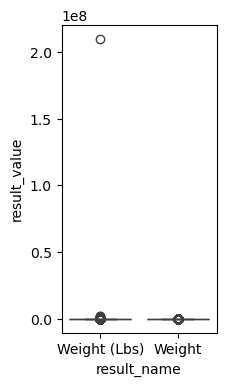

In [88]:
plt.figure(figsize = (2, 4))
sns.boxplot(test2_df, x = "result_name", y = "result_value")

plt.show()

Weight(Lbs) and Weight are the same category.

In [89]:
test2_df.loc[test2_df["result_value"] > 1500, :]

,result_name,result_value
40489,Weight (Lbs),1653.00
164332,Weight (Lbs),1741.90
194956,Weight (Lbs),1991.00
214540,Weight (Lbs),1601.00
236230,Weight (Lbs),1547.00
...,...,...
7305115,Weight (Lbs),2294.00
7531812,Weight (Lbs),23401.00
7600299,Weight (Lbs),2228.00
7613671,Weight (Lbs),19918.43


In [90]:
test2_df.loc[test2_df["result_value"] == 0.0, :]

,result_name,result_value
90031,Weight (Lbs),0.0
113520,Weight (Lbs),0.0
123336,Weight (Lbs),0.0
183032,Weight (Lbs),0.0
189298,Weight (Lbs),0.0
...,...,...
7528784,Weight (Lbs),0.0
7537738,Weight (Lbs),0.0
7657646,Weight (Lbs),0.0
7680591,Weight (Lbs),0.0


In [91]:
omr_df.loc[omr_df["result_value"] == "0.0", :]

,subject_id,chartdate,seq_num,result_name,result_value
3153479,14082222,2181-07-11,1,BMI (kg/m2),0.0
3190486,14129294,2112-10-17,1,BMI (kg/m2),0.0
3380184,14380537,2126-08-31,1,BMI (kg/m2),0.0
3593406,14656374,2140-03-05,1,BMI (kg/m2),0.0
3735175,14845506,2117-12-29,1,BMI (kg/m2),0.0
3878748,15032580,2146-10-30,1,BMI (kg/m2),0.0
6567676,18494931,2153-10-14,2,BMI (kg/m2),0.0
7586304,19794706,2198-10-29,1,BMI (kg/m2),0.0
7586308,19794706,2199-02-15,1,BMI (kg/m2),0.0


In [92]:
pd.set_option("display.max_rows", None)
display(omr_df.loc[omr_df["subject_id"] == 14082222, :])
pd.reset_option("display.max_rows")

,subject_id,chartdate,seq_num,result_name,result_value
3153389,14082222,2173-07-04,1,Blood Pressure,120/70
3153390,14082222,2173-07-04,1,BMI (kg/m2),36.3
3153391,14082222,2173-07-04,1,Height (Inches),72
3153392,14082222,2173-07-04,1,Weight (Lbs),268
3153393,14082222,2173-09-20,1,Blood Pressure,128/80
3153394,14082222,2173-09-20,1,BMI (kg/m2),36.1
3153395,14082222,2173-09-20,1,Weight (Lbs),266
3153396,14082222,2176-01-07,1,BMI (kg/m2),34.3
3153397,14082222,2176-01-07,1,Weight (Lbs),253
3153398,14082222,2176-01-16,1,BMI (kg/m2),34.6


Weight has many extreme values, 0.0 lbs to 1500+ lbs. Such ranges should be dropped

In [93]:
test2_df.loc[(test2_df["result_value"] != 0.0) & (test2_df["result_value"] < 5.0), :]

,result_name,result_value
43627,Weight (Lbs),1.0
141249,Weight (Lbs),1.0
146711,Weight (Lbs),1.0
279518,Weight (Lbs),1.0
306072,Weight (Lbs),1.0
...,...,...
7613111,Weight (Lbs),1.0
7647174,Weight (Lbs),1.0
7683507,Weight (Lbs),1.0
7684483,Weight (Lbs),1.0


In [94]:
omr_df.loc[omr_df["subject_id"] == 10058750, :]

,subject_id,chartdate,seq_num,result_name,result_value
43627,10058750,2149-09-06,1,Weight (Lbs),01
43628,10058750,2149-09-07,1,BMI (kg/m2),30.1
43629,10058750,2149-09-07,1,Height (Inches),73
43630,10058750,2149-09-07,1,Weight (Lbs),228
43631,10058750,2149-10-17,1,Blood Pressure,121/83
43632,10058750,2149-10-17,1,BMI (kg/m2),29.7
43633,10058750,2149-10-17,1,Height (Inches),73
43634,10058750,2149-10-17,1,Weight (Lbs),225
43635,10058750,2149-11-01,1,Blood Pressure,109/69
43636,10058750,2149-11-01,1,BMI (kg/m2),29.7


This guy is not 1 lb, given his other OMR at other dates (e.g. He is suddenly getting adult numbers after a day of OMR recording)

#### Height issue

Height has issues but checking if can merge first before trying to resolve

In [95]:
test3_df = omr_df.loc[omr_df["result_name"].str.contains("Height"), ["result_name", "result_value"]]

In [96]:
sorted(test3_df["result_value"].unique())

['.',
 '.62',
 '.64',
 '.65',
 '0',
 '00',
 '000',
 '0000',
 '00000',
 '001',
 '060.3',
 '1',
 '10',
 '100',
 '101',
 '106',
 '107',
 '108',
 '110',
 '111',
 '1111',
 '115',
 '116',
 '119',
 '12',
 '120',
 '122',
 '123',
 '124',
 '125',
 '130',
 '138',
 '14',
 '142',
 '144',
 '150',
 '151',
 '152.4',
 '152.40',
 '153',
 '154',
 '156',
 '157',
 '158',
 '159',
 '16',
 '160',
 '161',
 '162',
 '162.5',
 '162.56',
 '163',
 '165',
 '165.1',
 '165.5',
 '166',
 '167',
 '167.6',
 '167.64',
 '168',
 '17',
 '170',
 '170.18',
 '171',
 '172',
 '173',
 '173.2',
 '174',
 '175',
 '175.26',
 '177',
 '177.8',
 '178',
 '18',
 '180',
 '1815',
 '182',
 '183',
 '191',
 '193',
 '2',
 '209',
 '21.7',
 '23',
 '232',
 '25.59',
 '253',
 '27.5',
 '28',
 '3.15',
 '30',
 '302',
 '31.5',
 '32',
 '33',
 '3333',
 '34',
 '34.25',
 '34.5',
 '35',
 '35.5',
 '36',
 '37',
 '38',
 '38.5',
 '39.38',
 '39.5',
 '4',
 '4.10',
 '4.11',
 '4.8',
 '4.9',
 '40',
 '41',
 '410',
 '42',
 '43',
 '43.5',
 '44',
 '45',
 '45.5',
 '46',
 '4

Remove starting `.`

In [97]:
display(test3_df.loc[test3_df["result_value"].str[0] == "."])

# Convert them to 0, since it 0 will either be removed or be at 0 when changing from object to float64
test3_df["result_value"] = test3_df["result_value"].str.replace(r"^\.", "0", regex = True)

display(test3_df.loc[test3_df["result_value"].str[0] == "."])

,result_name,result_value
463857,Height (Inches),.
977576,Height,.
2735123,Height (Inches),.62
2735125,Height (Inches),.65
3859782,Height,.
4467276,Height,.
6082441,Height (Inches),.64
6105413,Height,.
6742030,Height,.


,result_name,result_value


In [98]:
test3_df = test3_df.astype({"result_value": "float64"})

In [99]:
test3_df.groupby("result_name")["result_value"].describe()

,count,mean,std,min,25%,50%,75%,max
result_name,,,,,,,,
Height,2365.0,65.418689,6.061470,0.0,62.50,65.50,68.5,152.4
Height (Inches),814964.0,65.673682,82.564783,0.0,62.75,65.25,68.0,73252.0


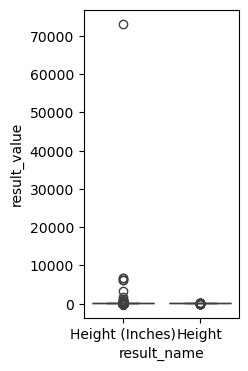

In [100]:
plt.figure(figsize = (2, 4))
sns.boxplot(test3_df, x = "result_name", y = "result_value")

plt.show()

Height (Inches) and Height are the same category.

In [101]:
test3_df.loc[test3_df["result_value"] > 110, :]

,result_name,result_value
7845,Height,152.40
203642,Height (Inches),152.40
212311,Height (Inches),175.00
292027,Height (Inches),162.56
314665,Height (Inches),168.00
...,...,...
7547676,Height (Inches),161.00
7582123,Height (Inches),152.40
7586305,Height (Inches),1815.00
7648210,Height (Inches),119.00


In [102]:
omr_df.loc[7547676, :]

omr_df.loc[omr_df["subject_id"] == 19747028, :]

,subject_id,chartdate,seq_num,result_name,result_value
7547675,19747028,2149-02-04,1,BMI (kg/m2),4.2
7547676,19747028,2149-02-04,1,Height (Inches),161
7547677,19747028,2149-02-04,1,Weight (Lbs),156.00
7547678,19747028,2149-02-22,1,Blood Pressure,119/53
7547679,19747028,2149-03-29,1,Blood Pressure,158/75
7547680,19747028,2149-05-31,1,BMI (kg/m2),24.5
7547681,19747028,2149-05-31,1,Height (Inches),65
7547682,19747028,2149-05-31,1,Weight (Lbs),147.00
7547683,19747028,2149-06-14,1,Blood Pressure,163/79
7547684,19747028,2149-10-06,1,Blood Pressure,151/76


In [103]:
CompareDataAndKeys(omr_df, patients_df, ["subject_id"])

All data under ['subject_id'] in left df exists in right df


### d_icd_diagnoses (Darren - hosp) Done!

- icd_code and icd_version together are unique

In [104]:
d_icd_diagnoses_df = pd.read_csv(f"{HOSP_PATH}/d_icd_diagnoses.csv")

In [105]:
ShapeHeadMissing(d_icd_diagnoses_df)

Shape: (112107, 3)


,icd_code,icd_version,long_title
0,0010,9,Cholera due to vibrio cholerae
1,0011,9,Cholera due to vibrio cholerae el tor
2,0019,9,"Cholera, unspecified"
3,0020,9,Typhoid fever
4,0021,9,Paratyphoid fever A


icd_code       0
icd_version    0
long_title     0
dtype: int64


In [106]:
VerifyUniqueKeys(d_icd_diagnoses_df, 
                 ["icd_code", "icd_version"])

['icd_code', 'icd_version'] is unique to table


### diagnoses_icd (Darren - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - d_icd_diagnoses - hosp
- Consider renaming this table from diagnoses_icd to icd_diagnoses to better suit standardisation with d_icd_diagnoses
    - or you can change d_icd_diagnoses to d_diagnoses_icd, whichever is preferred

In [107]:
diagnoses_icd_df = pd.read_csv(f"{HOSP_PATH}/diagnoses_icd.csv")

In [108]:
ShapeHeadMissing(diagnoses_icd_df)

Shape: (6364488, 5)


,subject_id,hadm_id,seq_num,icd_code,icd_version
0,10000032,22595853,1,5723,9
1,10000032,22595853,2,78959,9
2,10000032,22595853,3,5715,9
3,10000032,22595853,4,07070,9
4,10000032,22595853,5,496,9


subject_id     0
hadm_id        0
seq_num        0
icd_code       0
icd_version    0
dtype: int64


In [109]:
VerifyCatConsistency(diagnoses_icd_df, 
                     ["seq_num"])

seq_num
1     545507
2     531552
3     508643
4     482201
5     452724
6     421439
7     389019
8     356515
9     324023
10    292773
11    262899
12    234761
13    208723
14    185025
15    163067
16    143169
17    125003
18    108699
19     94256
20     81456
21     70210
22     60363
23     51816
24     44278
25     37853
26     32288
27     27481
28     23338
29     19774
30     16765
31     14103
32     11877
33      9936
34      8344
35      6955
36      5856
37      4831
38      3908
39      3058
Name: count, dtype: int64

In [110]:
CompareDataAndKeys(diagnoses_icd_df, patients_df, ["subject_id"])
CompareDataAndKeys(diagnoses_icd_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(diagnoses_icd_df, d_icd_diagnoses_df, ["icd_code", "icd_version"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['icd_code', 'icd_version'] in left df exists in right df


### drgcodes (Darren - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
- The drug details (type, code, description) should be unique. Note that this was not the case in the data.
    - Consider creating a separate table to fix this (d_drgcodes)
        - Code to create d_drgcodes in Darren's GitHub
        - Note that the drug descriptions have to be manually changed.

In [111]:
drgcodes_df = pd.read_csv(f"{HOSP_PATH}/drgcodes.csv")

In [112]:
ShapeHeadMissing(drgcodes_df)

Shape: (761856, 7)


,subject_id,hadm_id,drg_type,drg_code,description,drg_severity,drg_mortality
0,10000032,22595853,APR,283,OTHER DISORDERS OF THE LIVER,2.0,2.0
1,10000032,22595853,HCFA,442,"DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W CC",NaN,NaN
2,10000032,22841357,APR,279,HEPATIC COMA AND OTHER MAJOR ACUTE LIVER DISORDERS,3.0,2.0
3,10000032,22841357,HCFA,442,"DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W CC",NaN,NaN
4,10000032,25742920,APR,283,OTHER DISORDERS OF THE LIVER,3.0,2.0


subject_id            0
hadm_id               0
drg_type              0
drg_code              0
description           0
drg_severity     394925
drg_mortality    394925
dtype: int64


In [113]:
print(drgcodes_df.loc[(drgcodes_df["drg_severity"].isna()) & (drgcodes_df["drg_mortality"].isna()), :].shape)

print("All missing drg_severity would result in missing drg_mortality")

(394925, 7)
All missing drg_severity would result in missing drg_mortality


In [114]:
drgcodes_dup_description = drgcodes_df.groupby(["drg_type", "drg_code"])["description"].nunique()
drgcodes_dup_description[drgcodes_dup_description > 1]

drg_type  drg_code
HCFA      1           2
          3           2
          4           2
          5           2
          6           2
                     ..
          982         2
          983         2
          987         2
          988         2
          989         2
Name: description, Length: 691, dtype: int64

In [115]:
drgcodes_df.loc[(drgcodes_df["drg_type"] == "HCFA") &
                (drgcodes_df["drg_code"] == 65), :].values

array([[10003299, 29323205, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION W CC OR TPA IN 24 HRS',
        nan, nan],
       [10006277, 25610553, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION W CC', nan, nan],
       [10011365, 26948481, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION W CC', nan, nan],
       ...,
       [19990757, 22881459, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION W CC', nan, nan],
       [19995012, 22736185, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION WITH CC OR TPA IN 24 HOUR',
        nan, nan],
       [19999840, 26071774, 'HCFA', ...,
        'INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION W CC', nan, nan]],
      dtype=object)

In [116]:
drgcodes_df.loc[(drgcodes_df["drg_type"] == "HCFA") & 
                (drgcodes_df["drg_code"] == 441), :].values

array([[10011427, 22216667, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W MCC', nan, nan],
       [10021487, 27660781, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W MCC', nan, nan],
       [10039708, 21459630, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIG, CIRR, ALC HEPA W MCC', nan,
        nan],
       ...,
       [19979915, 27747060, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIGNANCY, CIRRHOSIS OR ALCOHOLIC HEPATITIS W',
        nan, nan],
       [19992875, 20600989, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W MCC', nan, nan],
       [19998878, 29356037, 'HCFA', ...,
        'DISORDERS OF LIVER EXCEPT MALIG,CIRR,ALC HEPA W MCC', nan, nan]],
      dtype=object)

Multiple of the same drug type and drug code have different description. Fix it for consistency

In [117]:
CompareDataAndKeys(drgcodes_df, patients_df, ["subject_id"])
CompareDataAndKeys(drgcodes_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


### d_hcpcs (Darren - hosp) Done!

- code is unique
- To fix missing data in `long_description`, merge `short_description` or `long_description` into a new column (e.g. `description`), based on whichever (`short_description` or `long_description`) has more infomration
    - This works because there are no missing values in `short_description`

In [118]:
d_hcpcs_df = pd.read_csv(f"{HOSP_PATH}/d_hcpcs.csv")

In [119]:
ShapeHeadMissing(d_hcpcs_df)

Shape: (89208, 4)


,code,category,long_description,short_description
0,00000,NaN,NaN,Invalid Code
1,0001F,2.0,NaN,Composite measures
2,0002F,2.0,NaN,Composite measures
3,0003F,2.0,NaN,Composite measures
4,0004F,2.0,NaN,Composite measures


code                     0
category              6850
long_description     82408
short_description        0
dtype: int64


In [120]:
d_hcpcs_df.loc[d_hcpcs_df["category"].isna(), :]

,code,category,long_description,short_description
0,00000,NaN,NaN,Invalid Code
1825,0643T,NaN,NaN,Transcatheter Implantation and Removal Procedures
1826,0644T,NaN,NaN,Transcatheter Implantation and Removal Procedures
1827,0645T,NaN,NaN,Transcatheter Implantation and Removal Procedures
1828,0646T,NaN,NaN,Transcatheter Implantation and Removal Procedures
...,...,...,...,...
89203,XS,NaN,"Separate structure, a service that is distinct because it was performed on a separate organ/structure",Separate organ/structure
89204,XU,NaN,"Unusual non-overlapping service, the use of a service that is distinct because it does not overlap usual components of the main service",Unusual separate service
89205,ZA,NaN,Novartis/sandoz,Novartis/sandoz
89206,ZB,NaN,Pfizer/hospira,Pfizer/hospira


Thats fine, category can be NA

In [121]:
d_hcpcs_df.loc[d_hcpcs_df["long_description"].isna(), "short_description"].value_counts()

short_description
Musculoskeletal system                                                                                                                                                10000
Digestive system                                                                                                                                                       9510
Integumentary system                                                                                                                                                   9460
Diagnostic imaging                                                                                                                                                     6500
Cardiovascular system                                                                                                                                                  4790
                                                                                                                          

In [122]:
d_hcpcs_df.loc[d_hcpcs_df["long_description"].str.len() > d_hcpcs_df["short_description"].str.len(), :]

,code,category,long_description,short_description
82397,A0021,NaN,"Ambulance service, outside state per mile, transport (medicaid only)",Outside state ambulance serv
82398,A0080,NaN,"Non-emergency transportation, per mile - vehicle provided by volunteer (individual or organization), with no vested interest",Noninterest escort in non er
82399,A0090,NaN,"Non-emergency transportation, per mile - vehicle provided by individual (family member, self, neighbor) with vested interest",Interest escort in non er
82400,A0100,NaN,Non-emergency transportation; taxi,Nonemergency transport taxi
82401,A0110,NaN,"Non-emergency transportation and bus, intra or inter state carrier",Nonemergency transport bus
...,...,...,...,...
89200,X5,NaN,"Diagnostic services requested by another clinician: for reporting services by a clinician who furnishes care to the patient only as requested by another clinician or subsequent and related services requested by another clinician; this modifier is reported for patient relationships that may not be adequately captured by the above alternative categories; reporting clinician service examples include but are not limited to, the radiologist's interpretation of an imaging study requested by another clinician",Svc req by another clinician
89201,XE,NaN,"Separate encounter, a service that is distinct because it occurred during a separate encounter",Separate encounter
89202,XP,NaN,"Separate practitioner, a service that is distinct because it was performed by a different practitioner",Separate practitioner
89203,XS,NaN,"Separate structure, a service that is distinct because it was performed on a separate organ/structure",Separate organ/structure


Combine the descriptions into one column, can also fix missing data in `long_description`

In [123]:
VerifyUniqueKeys(d_hcpcs_df,
                 ["code"])

['code'] is unique to table


### hcpcsevents (Darren - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - d_hcpcs - hosp
- Consider changing the column name `short_description` to `description`
- Consider changing hcpcs_cd to hcpcs_code?

In [124]:
hcpcsevents_df = pd.read_csv(f"{HOSP_PATH}/hcpcsevents.csv")

In [125]:
ShapeHeadMissing(hcpcsevents_df)

Shape: (186074, 6)


,subject_id,hadm_id,chartdate,hcpcs_cd,seq_num,short_description
0,10000068,25022803,2160-03-04,99218,1,Hospital observation services
1,10000084,29888819,2160-12-28,G0378,1,Hospital observation per hr
2,10000108,27250926,2163-09-27,99219,1,Hospital observation services
3,10000117,22927623,2181-11-15,43239,1,Digestive system
4,10000117,22927623,2181-11-15,G0378,2,Hospital observation per hr


subject_id           0
hadm_id              0
chartdate            0
hcpcs_cd             0
seq_num              0
short_description    0
dtype: int64


In [126]:
VerifyCatConsistency(hcpcsevents_df,
                     ["seq_num"])

seq_num
1     145364
2      24394
3       9488
4       3944
5       1469
6        652
7        332
8        172
9         95
10        60
11        38
12        25
13        19
14        12
15        10
Name: count, dtype: int64

In [127]:
CompareDataAndKeys(hcpcsevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(hcpcsevents_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


In [128]:
print(hcpcsevents_df["hcpcs_cd"].isin(d_hcpcs_df["code"]).all())

print(f"All data under hcpcs_cd of hcpcsevents table exists in code of d_hcpcs table")

True
All data under hcpcs_cd of hcpcsevents table exists in code of d_hcpcs table


### caregiver (Sean - icu) Done!

- caregiver_id is unique

In [129]:
caregiver_df = pd.read_csv(f"{ICU_PATH}/caregiver.csv")

In [130]:
ShapeHeadMissing(caregiver_df)

Shape: (17984, 1)


,caregiver_id
0,3
1,4
2,6
3,9
4,12


caregiver_id    0
dtype: int64


In [131]:
VerifyUniqueKeys(caregiver_df,
                 ["caregiver_id"])

['caregiver_id'] is unique to table


### datetimeevents (Sean - icu)

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - d_items - icu
    - caregiver - icu
- <span style = "color:red;">Check with Sean:</span>
    - valueuom can be all consistent to Date since no difference between Date or Date and Time
        - [icu -> datetimeevents -> valueuom](https://mimic.mit.edu/docs/iv/modules/icu/datetimesevents.html#valueuom)
- warning can be changed from integer 0, 1 to boolean False, True

In [132]:
datetimeevents_df = pd.read_csv(f"{ICU_PATH}/datetimeevents.csv")

In [133]:
ShapeHeadMissing(datetimeevents_df)

Shape: (9979761, 10)


,subject_id,hadm_id,stay_id,caregiver_id,charttime,storetime,itemid,value,valueuom,warning
0,10000032,29079034,39553978,18704,2180-07-23 14:24:00,2180-07-23 14:24:00,225754,2180-07-23 14:24:00,Date,0
1,10000032,29079034,39553978,18704,2180-07-23 14:24:00,2180-07-23 14:24:00,225755,2180-07-23 14:24:00,Date,0
2,10000032,29079034,39553978,20925,2180-07-23 21:02:00,2180-07-23 21:02:00,225754,2180-07-23 00:00:00,Date,0
3,10000032,29079034,39553978,20925,2180-07-23 21:02:00,2180-07-23 21:02:00,225755,2180-07-23 00:00:00,Date,0
4,10000690,25860671,37081114,17393,2150-11-02 20:00:00,2150-11-03 04:53:00,225754,2150-11-02 04:53:00,Date,0


subject_id      0
hadm_id         0
stay_id         0
caregiver_id    0
charttime       0
storetime       0
itemid          0
value           0
valueuom        0
warning         0
dtype: int64


In [134]:
datetimeevents_df.loc[datetimeevents_df["itemid"] == 225754, "value"]

0          2180-07-23 14:24:00
2          2180-07-23 00:00:00
4          2150-11-02 04:53:00
8          2150-11-02 00:00:00
10         2150-11-02 00:00:00
                  ...         
9979748    2145-11-02 00:00:00
9979749    2145-11-02 00:00:00
9979754    2145-11-04 20:48:00
9979756    2145-11-02 00:00:00
9979759    2145-11-02 00:00:00
Name: value, Length: 686077, dtype: object

No issues with value above

In [135]:
VerifyCatConsistency(datetimeevents_df, 
                     ["valueuom", "warning"])

valueuom
Date             7153915
Date and Time    2825846
Name: count, dtype: int64

warning
0    9976940
1       2821
Name: count, dtype: int64

In [136]:
datetimeevents_df.loc[datetimeevents_df["valueuom"] == "Date and Time", :]

,subject_id,hadm_id,stay_id,caregiver_id,charttime,storetime,itemid,value,valueuom,warning
12,10000690,25860671,37081114,33125,2150-11-05 13:00:00,2150-11-05 13:01:00,224287,2150-11-04 00:00:00,Date and Time,0
13,10000690,25860671,37081114,33125,2150-11-05 13:01:00,2150-11-05 13:02:00,224279,2150-11-05 00:00:00,Date and Time,0
27,10001217,27703517,34592300,68375,2157-12-20 08:00:00,2157-12-20 08:32:00,224186,2157-12-14 02:34:00,Date and Time,0
29,10001217,27703517,34592300,68375,2157-12-20 12:00:00,2157-12-20 12:03:00,224186,2157-12-14 02:34:00,Date and Time,0
32,10001217,27703517,34592300,73184,2157-12-20 02:34:00,2157-12-20 02:35:00,224186,2157-12-14 02:34:00,Date and Time,0
...,...,...,...,...,...,...,...,...,...,...
9979716,19999840,21033226,38978960,93123,2164-09-16 08:39:00,2164-09-16 08:39:00,224279,2164-09-18 02:00:00,Date and Time,0
9979721,19999840,21033226,38978960,93123,2164-09-16 12:26:00,2164-09-16 12:26:00,224279,2164-09-18 02:00:00,Date and Time,0
9979726,19999840,21033226,38978960,93123,2164-09-16 16:09:00,2164-09-16 16:09:00,224279,2164-09-18 02:00:00,Date and Time,0
9979731,19999840,21033226,38978960,93123,2164-09-17 08:11:00,2164-09-17 08:11:00,224279,2164-09-18 02:00:00,Date and Time,0


In [137]:
CompareDataAndKeys(datetimeevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(datetimeevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(datetimeevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(datetimeevents_df, d_items_df, ["itemid"])
CompareDataAndKeys(datetimeevents_df, caregiver_df, ["caregiver_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df
All data under ['caregiver_id'] in left df exists in right df


### provider (Sean - hosp) Done!

- provider_id is unique

In [138]:
provider_df = pd.read_csv(f"{HOSP_PATH}/provider.csv")

In [139]:
ShapeHeadMissing(provider_df)

Shape: (42244, 1)


,provider_id
0,P00019
1,P0001J
2,P0001P
3,P000FQ
4,P000H1


provider_id    0
dtype: int64


In [140]:
VerifyUniqueKeys(provider_df,
                 ["provider_id"])

['provider_id'] is unique to table


### poe (Sean - hosp) Done!

- poe_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp
    - provider - hosp (Missing)
- Issues with data
    - order_subtype
        - Remove html tags from the value: `Neuraxial Procedure <b>(Anesthesia Only)</b>`
- <span style = "color:red;">Check with Sean:</span>
    - poe order lineage
        - Would you prefer to only keep orders that are currently running (i.e. discontinued_by_poe_id == NaN)?
        - Or keep the whole lineage
        - Most of the poe orders are not discontinued.
        - 41480217/52212109 (79.45%) are first poe orders (From discontinue_of_poe_id == NaN)
            - 7808854/52212109 (0.15%) of the first poe orders are discontinued
        - 41556491/52212109 (79.59%) are poe orders that are still existing (from discontinued_by_poe_id == NaN). They can be first or subsequent poe orders
    - Also I am not sure why this feature has weird missing values, see at the code end of this section

In [159]:
poe_df = pd.read_csv(f"{HOSP_PATH}/poe.csv")

In [160]:
ShapeHeadMissing(poe_df)

Shape: (52212109, 12)


,poe_id,poe_seq,subject_id,hadm_id,ordertime,order_type,order_subtype,transaction_type,discontinue_of_poe_id,discontinued_by_poe_id,order_provider_id,order_status
0,10000032-100,100,10000032,22841357,2180-06-26 22:09:02,Medications,NaN,New,NaN,NaN,P992IN,Inactive
1,10000032-101,101,10000032,22841357,2180-06-26 22:09:02,General Care,Code status,New,NaN,NaN,P992IN,Inactive
2,10000032-102,102,10000032,22841357,2180-06-26 22:09:02,Nutrition,Nutrition consult,New,NaN,NaN,P992IN,Inactive
3,10000032-103,103,10000032,22841357,2180-06-26 22:09:02,Blood Bank,Blood tests,New,NaN,NaN,P992IN,Inactive
4,10000032-104,104,10000032,22841357,2180-06-26 22:09:02,Lab,NaN,New,NaN,NaN,P992IN,Inactive


poe_id                           0
poe_seq                          0
subject_id                       0
hadm_id                          0
ordertime                        0
order_type                       0
order_subtype             32220166
transaction_type                 0
discontinue_of_poe_id     41480217
discontinued_by_poe_id    41556491
order_provider_id           308039
order_status                     0
dtype: int64


In [161]:
sorted(poe_df.loc[poe_df["order_subtype"].isna(), "order_type"].unique())

['IV therapy', 'Lab', 'Medications', 'Radiology']

In [162]:
poe_df.loc[poe_df["order_type"].isin(['IV therapy', 'Lab', 'Medications', 'Radiology']), 
            ["order_type", "order_subtype"]]\
        .groupby("order_type")["order_subtype"].unique()

order_type
IV therapy     [IV access, IV fluids, IV access request, Radiology OK to use line, nan, Radiology Tip confirmation OK to use line, 3CG or Radiology Tip confirmation OK to use line, IV Drip, Flushes, NICU and non-routine Nursery Diet Order, Access]
Lab                                                                                                                                                                                         [nan, CSF, Urine, Blood Gases/Whole Blood, Drug Monitoring]
Medications                                                                                                                                                                                            [nan, Medication, Pain Medication/Bowel Regimen]
Radiology                                                             [General Xray, CT Scan, Ultrasound, Interventional Radiology, Nuclear Med, Cross-Sectional Interventional Radiology, MRI, Noninvasive Vascular, Angio, Interventional Neuro, na

Can keep order_subtype empty since there is no direct relation to order_type

In [163]:
poe_df.loc[(poe_df["discontinue_of_poe_id"].isna()) &
            (-poe_df["discontinued_by_poe_id"].isna()), :]

,poe_id,poe_seq,subject_id,hadm_id,ordertime,order_type,order_subtype,transaction_type,discontinue_of_poe_id,discontinued_by_poe_id,order_provider_id,order_status
12,10000032-114,114,10000032,22841357,2180-06-27 17:50:27,ADT orders,Discharge,New,NaN,10000032-115,P87CLZ,Inactive
25,10000032-13,13,10000032,22595853,2180-05-06 20:37:14,Medications,NaN,New,NaN,10000032-14,P21AVM,Inactive
31,10000032-135,135,10000032,29079034,2180-07-23 09:12:41,Medications,NaN,New,NaN,10000032-136,P22YD4,Inactive
56,10000032-160,160,10000032,29079034,2180-07-23 15:11:33,General Care,Code status,New,NaN,10000032-198,P12N2O,Inactive
72,10000032-175,175,10000032,29079034,2180-07-23 23:52:55,ADT orders,Transfer,New,NaN,10000032-203,P433OW,Inactive
...,...,...,...,...,...,...,...,...,...,...,...,...
52212084,19999987-63,63,19999987,23865745,2145-11-03 14:46:19,Medications,NaN,New,NaN,19999987-64,P213X2,Inactive
52212087,19999987-66,66,19999987,23865745,2145-11-03 22:07:45,Medications,NaN,New,NaN,19999987-112,P213X2,Inactive
52212090,19999987-69,69,19999987,23865745,2145-11-04 02:18:56,Respiratory,Mechanical Ventilation,New,NaN,19999987-139,P213X2,Inactive
52212104,19999987-83,83,19999987,23865745,2145-11-04 08:39:45,Medications,NaN,New,NaN,19999987-85,P70GUP,Inactive


In [164]:
VerifyCatConsistency(poe_df, 
                     ["order_type", "order_subtype", "transaction_type", "order_status"],
                     ["order_type", "order_subtype", "transaction_type", "order_status"])

order_type
ADT orders        2776808
Blood Bank         666209
Cardiology         423253
Consults           826947
Critical Care       63390
General Care      7670925
Hemodialysis        55165
IV therapy        2747821
Lab               8908993
Medications      23295778
Neurology           39088
Nutrition         2131521
OB                  33818
Radiology         1876077
Respiratory        608476
TPN                 87840
Name: count, dtype: int64

order_subtype
3CG or Radiology Tip confirmation OK to use line       1495
Access                                                    2
Activity                                             998950
Acute Care Surgery                                     3906
Addiction                                              1850
Admit                                               1019546
Anesthesia (Chronic Pain Service)                      3027
Angio                                                 22762
BiPAP                                                 16049
Blood Gases/Whole Blood                                   2
Blood tests                                          409582
Brace and DME Orders                                   4721
CMFM                                                   4656
COVID-19 Precautions De-escalation                     3971
CPAP for OSA                                          36443
CSF                                                     228
CT Scan                   

transaction_type
Change     5714162
D/C        5017727
H             6903
New       41468286
T             5031
Name: count, dtype: int64

order_status
Active        152303
Inactive    52059806
Name: count, dtype: int64

In [165]:
CompareDataAndKeys(poe_df, patients_df, ["subject_id"])
CompareDataAndKeys(poe_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


In [166]:
print("check if all order_provider_id in poe_df exists in provider_id in provider_id")
set(poe_df["order_provider_id"].unique()) - set(provider_df["provider_id"].unique())

check if all order_provider_id in poe_df exists in provider_id in provider_id


{nan}

Above shows nan because there are some poe_df without order_provider_id. Looks good.

In [167]:
print("Check if all poe_id in poe_detail_df exists in poe_df")
set(poe_detail_df["poe_id"].unique()) - set(poe_df["poe_id"].unique())

Check if all poe_id in poe_detail_df exists in poe_df


set()

In [168]:
print("Check if all discontinue_of_poe_id in poe_df exists in poe_id in poe_df")
set(poe_df["discontinue_of_poe_id"].unique()) - set(poe_df["poe_id"].unique())

Check if all discontinue_of_poe_id in poe_df exists in poe_id in poe_df


{'13962855-98',
 '19368573-26',
 '10390531-138',
 '11369569-31',
 '13583790-32',
 '18719447-258',
 '10284837-38',
 '11784765-27',
 '12451204-35',
 '19812418-38',
 '15574823-481',
 '10605241-280',
 '10475701-1587',
 '10206590-121',
 '10774653-23',
 '16564743-1886',
 '19735018-10',
 '19403848-251',
 '15936930-90',
 '14044629-696',
 '13306463-39',
 '15575672-44',
 '17725086-403',
 '10916096-1728',
 '12904821-41',
 '18662407-509',
 '11419860-264',
 '13552622-23',
 '18460860-237',
 '12764579-85',
 '10490455-437',
 '19131039-24',
 '11846379-120',
 '10247690-546',
 '17414299-78',
 '14925002-594',
 '16134262-26',
 '18550346-17',
 '19957285-133',
 '14769066-64',
 '12371954-232',
 '10407265-6',
 '19469858-428',
 '18475468-95',
 '13092823-141',
 '11126801-74',
 '19545860-268',
 '17298353-340',
 '19244736-147',
 '17972219-236',
 '10974358-25',
 '14288515-81',
 '14821176-299',
 '15319001-244',
 '16380789-52',
 '16382270-92',
 '12340885-431',
 '13039253-207',
 '10882203-241',
 '19288975-38',
 '13285

In [169]:
print("Check if all discontinued_by_poe_id in poe_df exists in poe_id in poe_df")
set(poe_df["discontinued_by_poe_id"].unique()) - set(poe_df["poe_id"].unique())

Check if all discontinued_by_poe_id in poe_df exists in poe_id in poe_df


{'11788497-94',
 '19553666-380',
 '17809522-1781',
 '19603912-219',
 '12623055-173',
 '18753289-326',
 '11465141-336',
 '12701519-1373',
 '18753289-329',
 '17707835-71',
 '13632905-186',
 '16615140-656',
 '18615660-287',
 '17332817-277',
 '19553666-379',
 '11383359-1614',
 '15947104-112',
 '13120988-206',
 '11340773-414',
 '15158294-238',
 '15429073-95',
 '19739493-84',
 '15614309-64',
 '15664993-447',
 '14284006-136',
 '18892314-119',
 '13496410-252',
 '17434758-133',
 '17809522-1783',
 '17434758-141',
 '19871070-469',
 '15203693-79',
 '14566049-61',
 '14126394-213',
 '19739493-100',
 '12071000-323',
 '16059065-274',
 '18823151-520',
 '15947104-100',
 '10676055-173',
 '15834858-89',
 '16122037-188',
 '17809522-1796',
 '13572263-88',
 '15394378-136',
 '16716163-133',
 '13771243-132',
 '19471200-301',
 '10431675-241',
 '19042997-170',
 '19553666-364',
 '10176453-472',
 '19435202-166',
 '15158294-240',
 '14239389-61',
 '19553666-361',
 '16059065-313',
 '14284006-133',
 '16789416-114',
 '

In [170]:
poe_df.loc[(poe_df["poe_id"] == "19553666-377") |
            (poe_df["discontinue_of_poe_id"] == "19553666-377") |
            (poe_df["discontinued_by_poe_id"] == "19553666-377"), :]

,poe_id,poe_seq,subject_id,hadm_id,ordertime,order_type,order_subtype,transaction_type,discontinue_of_poe_id,discontinued_by_poe_id,order_provider_id,order_status
49852464,19553666-66,66,19553666,25461540,2140-12-31 06:04:00,Medications,NaN,New,NaN,19553666-377,P8688R,Inactive


### poe_detail (Sean - hosp) Done!

- Requires:
    - patients - hosp
    - poe - hosp
- field_values contains data that are either DateTime or String values
- For those that are string values, the data is inconsistent,  with extra whitespaces and capitalisations
    - 'BOTH EYES', 'BOTH EYES '
    - 'IU  BOLUS', 'IU BOLUS'
    - 'IU  DRIP', 'IU DRIP'
    - 'IV','IV '
    - 'IV   BOLUS', 'IV  BOLUS', 'IV BOLUS'
    - 'IV   DRIP', 'IV  DRIP', 'IV DRIP'
    - 'IV INFUSION', 'IV Infusion'
    - 'neb', 'neb '

In [141]:
poe_detail_df = pd.read_csv(f"{HOSP_PATH}/poe_detail.csv")

In [142]:
ShapeHeadMissing(poe_detail_df)

Shape: (8504982, 5)


,poe_id,poe_seq,subject_id,field_name,field_value
0,10000032-101,101,10000032,Code status,Resuscitate (Full code)
1,10000032-109,109,10000032,Admit category,Admit to inpatient
2,10000032-109,109,10000032,Admit to,Medicine
3,10000032-114,114,10000032,Admit category,Admit to inpatient
4,10000032-114,114,10000032,Discharge Planning,Finalized


poe_id         0
poe_seq        0
subject_id     0
field_name     0
field_value    0
dtype: int64


In [143]:
VerifyCatConsistency(poe_detail_df,
                     ["field_name"], 
                     ["field_name"])

field_name
Admit category         1495259
Admit to               1145869
Code status             271809
Consult Status          108789
Consult Status Time     108789
Discharge Planning      596494
Discharge When          547289
Indication               41009
Level of Urgency        125371
Route                  3229027
Transfer to             214168
Tubes & Drains type     621109
Name: count, dtype: int64

In [144]:
sorted(poe_detail_df["field_value"].unique())

['1 PUFF',
 '2 PUFFS',
 '2 Puffs',
 '2 drops in R eye ',
 '2 puffs',
 '2 puffs BID',
 '2110-01-12 09:21:12',
 '2110-01-13 13:58:55',
 '2110-01-15 14:03:50',
 '2110-01-16 08:08:08',
 '2110-01-16 08:08:25',
 '2110-01-16 08:28:08',
 '2110-01-17 10:51:19',
 '2110-01-18 12:01:15',
 '2110-01-19 11:08:24',
 '2110-01-19 14:48:18',
 '2110-01-21 11:01:16',
 '2110-01-26 08:27:28',
 '2110-01-29 05:36:05',
 '2110-01-29 07:18:06',
 '2110-01-31 09:40:10',
 '2110-01-31 12:42:35',
 '2110-01-31 14:01:18',
 '2110-02-01 08:04:26',
 '2110-02-02 21:48:40',
 '2110-02-04 11:09:40',
 '2110-02-05 09:52:32',
 '2110-02-07 14:40:14',
 '2110-02-08 08:51:50',
 '2110-02-08 09:11:05',
 '2110-02-08 09:43:31',
 '2110-02-08 15:23:28',
 '2110-02-09 10:54:29',
 '2110-02-09 17:57:27',
 '2110-02-10 10:44:32',
 '2110-02-10 10:56:33',
 '2110-02-10 13:32:42',
 '2110-02-11 08:06:24',
 '2110-02-11 13:29:31',
 '2110-02-12 10:06:54',
 '2110-02-12 10:10:04',
 '2110-02-12 13:59:47',
 '2110-02-12 14:57:47',
 '2110-02-13 06:28:34',
 '2

In [145]:
sorted(poe_detail_df.loc[poe_detail_df["field_value"].str[0] != "2", "field_value"].unique())

['1 PUFF',
 '8 puffs',
 'AS',
 'AU',
 'Accepted',
 'Admit to PACU',
 'Admit to inpatient',
 'Antibiotics',
 'BOTH EARS',
 'BOTH EYES',
 'BOTH EYES ',
 'BU',
 'BUCCAL',
 'Biliary Tube (T tube)',
 'Blood products- FFP',
 'Blood products- Platelets',
 'Blood products- Red cells',
 'CMED - Blue',
 'CMED - Gold',
 'CMED - Red',
 'CMED - Silver',
 'Cardiology NP',
 'Chemo',
 'Chest tube',
 'Closed suction drain',
 'DIALYS',
 'DNAR (DO NOT attempt resuscitation for cardiac arrest) ',
 'DWELL',
 'Discharge Now',
 'Do not resuscitate (DNR/DNI)',
 'Drops',
 'EACH NOSTRIL',
 'ED',
 'ED - Observation',
 'ET',
 'FLUSH',
 'Fecal Management System, Flexiseal',
 'Fecal/Stool Management System',
 'Femoral Vein',
 'Fetal Injection',
 'Finalized',
 'Full code  (attempt resuscitation)',
 'G TUBE',
 'G tube',
 'G-tube',
 'GJ tube',
 'GT',
 'GU',
 'GYN',
 'General Surgery',
 'Hydration',
 'IA',
 'ICU',
 'ID',
 'IH',
 'IM',
 'IM/SC',
 'IMPELLA',
 'IN',
 'INH',
 'INHALATION',
 'INHALED',
 'INTRA-GESTATIONAL S

In [146]:
poe_detail_df.loc[poe_detail_df["field_value"].str[0] == "2", "field_name"].value_counts().sort_index()

field_name
Consult Status Time    108789
Route                       7
Name: count, dtype: int64

In [147]:
poe_detail_df.loc[(poe_detail_df["field_name"] == "Consult Status Time") & 
                    (poe_detail_df["field_value"].str[0] != "2"), :]

,poe_id,poe_seq,subject_id,field_name,field_value


In [148]:
poe_detail_df.loc[(poe_detail_df["field_name"] == "Route") & 
                    (poe_detail_df["field_value"].str[0] != "2"), :]

,poe_id,poe_seq,subject_id,field_name,field_value
89,10000161-23,23,10000161,Route,IV
90,10000161-28,28,10000161,Route,PO/NG
91,10000161-30,30,10000161,Route,PO/NG
92,10000161-31,31,10000161,Route,PO/NG
93,10000161-32,32,10000161,Route,PO
...,...,...,...,...,...
8504835,19999784-2296,2296,19999784,Route,IV
8504836,19999784-2308,2308,19999784,Route,PO/NG
8504837,19999784-2309,2309,19999784,Route,IV
8504838,19999784-2312,2312,19999784,Route,PO/NG


In [149]:
poe_detail_df.loc[(poe_detail_df["field_name"] == "Route") & 
                    (poe_detail_df["field_value"].str[0] != "2"), "field_value"].value_counts()

field_value
PO/NG            1184117
IV                969029
PO                451981
SC                190875
IM                 85621
                  ...   
intra uterine          1
ear                    1
INHALED                1
Intravesical           1
supp                   1
Name: count, Length: 219, dtype: int64

In [150]:
poe_detail_df.loc[poe_detail_df["field_name"] == "Consult Status", :]

,poe_id,poe_seq,subject_id,field_name,field_value
58,10000084-56,56,10000084,Consult Status,Accepted
274,10000947-45,45,10000947,Consult Status,Accepted
590,10001401-972,972,10001401,Consult Status,Accepted
628,10001667-256,256,10001667,Consult Status,Accepted
774,10001843-91,91,10001843,Consult Status,Accepted
...,...,...,...,...,...
8503707,19997911-734,734,19997911,Consult Status,Accepted
8504656,19999784-1904,1904,19999784,Consult Status,Accepted
8504714,19999784-2048,2048,19999784,Consult Status,Accepted
8504853,19999784-339,339,19999784,Consult Status,Accepted


In [151]:
poe_detail_df.loc[poe_detail_df["subject_id"] == 10000084, :]

,poe_id,poe_seq,subject_id,field_name,field_value
51,10000084-30,30,10000084,Admit category,Place in observation
52,10000084-30,30,10000084,Admit to,Medicine
53,10000084-32,32,10000084,Admit category,Admit to inpatient
54,10000084-32,32,10000084,Admit to,Medicine
55,10000084-40,40,10000084,Code status,Full code (attempt resuscitation)
56,10000084-55,55,10000084,Admit category,Admit to inpatient
57,10000084-55,55,10000084,Admit to,Medicine
58,10000084-56,56,10000084,Consult Status,Accepted
59,10000084-56,56,10000084,Consult Status Time,2160-11-23 06:15:06
60,10000084-56,56,10000084,Level of Urgency,Routine (within 24 hours)


In [152]:
poe_detail_df.loc[poe_detail_df["field_name"] == "Consult Status", "field_value"].value_counts()

field_value
Accepted               103701
Placed Under Review      5088
Name: count, dtype: int64

In [153]:
poe_detail_df.loc[(poe_detail_df["field_name"] == "Consult Status") &
                    (poe_detail_df["field_value"] == "Placed Under Review"), :]

,poe_id,poe_seq,subject_id,field_name,field_value
1752,10002348-74,74,10002348,Consult Status,Placed Under Review
6257,10006924-164,164,10006924,Consult Status,Placed Under Review
6702,10008077-333,333,10008077,Consult Status,Placed Under Review
8482,10010278-447,447,10010278,Consult Status,Placed Under Review
11145,10012206-135,135,10012206,Consult Status,Placed Under Review
...,...,...,...,...,...
8502305,19996783-476,476,19996783,Consult Status,Placed Under Review
8502326,19996783-609,609,19996783,Consult Status,Placed Under Review
8502351,19996783-806,806,19996783,Consult Status,Placed Under Review
8503202,19997561-418,418,19997561,Consult Status,Placed Under Review


In [154]:
poe_detail_df.loc[poe_detail_df["subject_id"] == 10002348, :]

,poe_id,poe_seq,subject_id,field_name,field_value
1741,10002348-118,118,10002348,Tubes & Drains type,Indwelling urinary catheter (IUC) - Foley
1742,10002348-136,136,10002348,Admit category,Admit to inpatient
1743,10002348-136,136,10002348,Admit to,Surgery
1744,10002348-198,198,10002348,Admit category,Admit to inpatient
1745,10002348-198,198,10002348,Transfer to,Surgery
1746,10002348-258,258,10002348,Admit category,Admit to inpatient
1747,10002348-258,258,10002348,Discharge Planning,Finalized
1748,10002348-259,259,10002348,Admit category,Admit to inpatient
1749,10002348-259,259,10002348,Discharge When,Discharge Now
1750,10002348-46,46,10002348,Admit category,Admit to inpatient


All patients with a Consult Statuses `field_name` are followed by a Consult Status Time also in `field_name`. The Consult Status Time would have a DateTime in field_value.

However, not all field_value with DateTime are Consult Status Time, as some are under Route, where it is a mixture of DateTimes and String values

In [155]:
poe_detail_df.loc[:, ["poe_id", "poe_seq", "subject_id"]].value_counts().sort_values()

poe_id         poe_seq  subject_id
11738880-86    86       11738880      1
17683383-269   269      17683383      1
17683383-270   270      17683383      1
10834521-79    79       10834521      1
17683383-272   272      17683383      1
                                     ..
12501011-67    67       12501011      3
14091176-223   223      14091176      3
13917544-1115  1115     13917544      3
14395454-65    65       14395454      3
11242982-1097  1097     11242982      3
Name: count, Length: 6814885, dtype: int64

In [156]:
poe_detail_df.loc[poe_detail_df["poe_id"] == "11774442-1129", :]

,poe_id,poe_seq,subject_id,field_name,field_value
1498096,11774442-1129,1129,11774442,Consult Status,Accepted
1498097,11774442-1129,1129,11774442,Consult Status Time,2140-01-08 16:12:09
1498098,11774442-1129,1129,11774442,Level of Urgency,Routine (within 24 hours)


In [157]:
poe_detail_df[poe_detail_df.duplicated(keep = False)]

,poe_id,poe_seq,subject_id,field_name,field_value


There are no completely duplicated rows

In [158]:
CompareDataAndKeys(poe_detail_df, patients_df, ["subject_id"])

All data under ['subject_id'] in left df exists in right df


### chartevents (Sean - icu) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - icustays - icu
    - d_items - icu
    - caregiver - icu
- <span style = "color:red;">Check with Sean:</span>
    - charttime vs storetime (Same issue with labevents and prescriptions)
        - Check issues where storetime is recorded after charttime and determine if it as issue knowing so. Can decide to switch it up
        - [icu -> chartevents -> charttime/storetime](https://mimic.mit.edu/docs/iv/modules/icu/chartevents.html#charttime-storetime)
    - Note that with the way how value, valuenum and valueuom is setup, where they can accept string and numbers (force type to string), they can have missing values

In [171]:
chartevents_df = pd.read_csv(f"{ICU_PATH}/chartevents.csv", nrows = 10000000)

In [172]:
ShapeHeadMissing(chartevents_df)

Shape: (10000000, 11)


,subject_id,hadm_id,stay_id,caregiver_id,charttime,storetime,itemid,value,valuenum,valueuom,warning
0,10000032,29079034,39553978,18704.0,2180-07-23 12:36:00,2180-07-23 14:45:00,226512,39.4,39.4,kg,0.0
1,10000032,29079034,39553978,18704.0,2180-07-23 12:36:00,2180-07-23 14:45:00,226707,60,60.0,Inch,0.0
2,10000032,29079034,39553978,18704.0,2180-07-23 12:36:00,2180-07-23 14:45:00,226730,152,152.0,cm,0.0
3,10000032,29079034,39553978,18704.0,2180-07-23 14:00:00,2180-07-23 14:18:00,220048,SR (Sinus Rhythm),NaN,NaN,0.0
4,10000032,29079034,39553978,18704.0,2180-07-23 14:00:00,2180-07-23 14:18:00,224642,Oral,NaN,NaN,0.0


subject_id            0
hadm_id               0
stay_id               0
caregiver_id     365369
charttime             0
storetime         13794
itemid                0
value            286408
valuenum        6093848
valueuom        7567039
warning           13794
dtype: int64


In [173]:
chartevents_df.loc[chartevents_df["storetime"].isna(), :].head()

,subject_id,hadm_id,stay_id,caregiver_id,charttime,storetime,itemid,value,valuenum,valueuom,warning
1275,10000690,25860671,37081114,17393.0,2150-11-03 01:58:28,NaN,220001,".H/O pneumonia, other",NaN,NaN,NaN
1276,10000690,25860671,37081114,17393.0,2150-11-03 01:58:28,NaN,220001,Hypotension (not Shock),NaN,NaN,NaN
2581,10000690,25860671,37081114,33125.0,2150-11-05 20:12:22,NaN,220001,Atrial fibrillation (Afib),NaN,NaN,NaN
2582,10000690,25860671,37081114,33125.0,2150-11-05 20:12:22,NaN,220001,Disturbed Sleep Pattern,NaN,NaN,NaN
2583,10000690,25860671,37081114,33125.0,2150-11-05 20:12:22,NaN,220001,"Fever, unknown origin (FUO, Hyperthermia, Pyrexia)",NaN,NaN,NaN


In [174]:
test4_df = chartevents_df.loc[-chartevents_df["storetime"].isna(), ["charttime", "storetime"]]

In [175]:
test4_df["charttime"] = pd.to_datetime(test4_df["charttime"])
test4_df["storetime"] = pd.to_datetime(test4_df["storetime"])

In [176]:
test4_df.head()

,charttime,storetime
0,2180-07-23 12:36:00,2180-07-23 14:45:00
1,2180-07-23 12:36:00,2180-07-23 14:45:00
2,2180-07-23 12:36:00,2180-07-23 14:45:00
3,2180-07-23 14:00:00,2180-07-23 14:18:00
4,2180-07-23 14:00:00,2180-07-23 14:18:00


In [177]:
test4_df.loc[test4_df["charttime"] > test4_df["storetime"], :]

,charttime,storetime
154,2180-07-23 15:00:00,2180-07-23 14:32:00
155,2180-07-23 15:00:00,2180-07-23 14:32:00
156,2180-07-23 15:00:00,2180-07-23 14:32:00
157,2180-07-23 15:00:00,2180-07-23 14:32:00
158,2180-07-23 15:00:00,2180-07-23 14:32:00
...,...,...
9999995,2153-01-14 20:00:00,2153-01-14 19:39:00
9999996,2153-01-14 20:00:00,2153-01-14 19:39:00
9999997,2153-01-14 20:00:00,2153-01-14 19:39:00
9999998,2153-01-14 20:00:00,2153-01-14 19:39:00


873691/10000000 About 8.74% of the data shows the storetime recorded after charttime. Should we remove it?

In [178]:
CompareDataAndKeys(chartevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(chartevents_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(chartevents_df, icustays_df, ["stay_id"])
CompareDataAndKeys(chartevents_df, d_items_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['stay_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


In [179]:
print("Check if all caregiver_id in chartevents_df exists in caregiver_id in cargiver_df")
set(chartevents_df["caregiver_id"].unique()) - set(caregiver_df["caregiver_id"].unique())

Check if all caregiver_id in chartevents_df exists in caregiver_id in cargiver_df


{np.float64(nan)}

NaN is fine here since there are missing caregivers in chartevents table

### d_labitems (Midhun - hosp) Done!

- itemid is unique
    - Note that label, fluid and category are supposed to be a unique tuple. but this is not the case in our dataset
        - Happy to leave it as it is
        - [hosp -> d_labitems](https://mimic.mit.edu/docs/iv/modules/hosp/d_labitems.html#d_labitems)
- There is a label with one whitespace, set it to NaN
    - itemid = 51905

In [180]:
d_labitems_df = pd.read_csv(f"{HOSP_PATH}/d_labitems.csv")

In [181]:
ShapeHeadMissing(d_labitems_df)

Shape: (1650, 4)


,itemid,label,fluid,category
0,50801,Alveolar-arterial Gradient,Blood,Blood Gas
1,50802,Base Excess,Blood,Blood Gas
2,50803,"Calculated Bicarbonate, Whole Blood",Blood,Blood Gas
3,50804,Calculated Total CO2,Blood,Blood Gas
4,50805,Carboxyhemoglobin,Blood,Blood Gas


itemid      0
label       4
fluid       0
category    0
dtype: int64


In [182]:
d_labitems_df.loc[d_labitems_df["label"].isna(), :]

,itemid,label,fluid,category
887,51771,NaN,Blood,Chemistry
1045,51955,NaN,Stool,Chemistry
1461,52374,NaN,Other Body Fluid,Hematology
1627,53168,NaN,Other Body Fluid,Chemistry


In [183]:
VerifyCatConsistency(d_labitems_df,
                     ["label", "fluid", "category"],
                     ["label", "fluid", "category"])

label
                                               1
 Rbc                                           1
% Hemoglobin A1c                               1
% Ionized Calcium                              1
% Parasitemia                                  1
(Albumi                                        1
(Albumin)                                      6
11-Deoxycorticosterone                         1
17-Hydroxycorticosteroids                      1
17-Ketosteroids, Urine                         1
24 Hr                                          1
24 hr Calcium                                  1
24 hr Creatinine                               1
24 hr Protein                                  1
25-OH Vitamin D                                1
3t                                             1
4t                                             1
5' Nucleotidase                                1
5-HIAA, Urine                                  1
72 Hr Fat                                      2
<Albumin>     

fluid
Ascites                 68
Blood                  821
Bone Marrow             63
Cerebrospinal Fluid    101
Fluid                    5
I                        1
Joint Fluid             72
Other Body Fluid       201
Pleural                 69
Q                        9
Stool                   46
Urine                  194
Name: count, dtype: int64

category
Blood Gas      65
Chemistry     800
Hematology    785
Name: count, dtype: int64

In [184]:
d_labitems_df.loc[d_labitems_df["label"] == " ", :]

,itemid,label,fluid,category
998,51905,,Other Body Fluid,Chemistry


In [185]:
VerifyUniqueKeys(d_labitems_df,
                 ["itemid"])

['itemid'] is unique to table


In [186]:
VerifyUniqueKeys(d_labitems_df,
                 ["label", "fluid", "category"])

['label', 'fluid', 'category'] is not unique to table


In [187]:
d_labitems_df[d_labitems_df.loc[:, ["label", "fluid", "category"]].duplicated(keep = False)]

,itemid,label,fluid,category
5,50806,"Chloride, Whole Blood",Blood,Blood Gas
11,50813,Lactate,Blood,Blood Gas
20,50822,"Potassium, Whole Blood",Blood,Blood Gas
22,50824,"Sodium, Whole Blood",Blood,Blood Gas
60,50862,Albumin,Blood,Chemistry
...,...,...,...,...
1558,53087,Amylase,Blood,Chemistry
1560,53089,"Bilirubin, Total",Blood,Chemistry
1564,53096,"Protein, Total",Blood,Chemistry
1600,53139,Aldosterone,Blood,Chemistry


### microbiologyevents (Midhun - hosp) Done!

- microevent_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp (Missing)
    - provider - hosp (Missing)
- Note that this table can have missing admissions
- <span style = "color:red;">Check with Midhun:</span>
    - You can create mapping tables for spec (spec_itemid, spec_type_desc), test (test_itemid, test_name), org (org_itemid, org_name), ab (ab_itemid, ab_name)
        - Note: There is a unique spec_itemid with a missing spec_type_desc. We can give it a spec_type_desc then to remove missing values
    - Since the unknown interpretations D, N and Z seems to have use but is unspecified, do not remove them but can record them all as unknown
        - [hosp -> microbiologyevents -> interpretation](https://mimic.mit.edu/docs/iv/modules/hosp/microbiologyevents.html#interpretation)

In [188]:
microbiologyevents_df = pd.read_csv(f"{HOSP_PATH}/microbiologyevents.csv")

In [189]:
microbiologyevents_df.head(1)

,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
0,1,10000032,NaN,1304715,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70046,IMMUNOLOGY,1,2180-03-26 00:00:00,2180-03-26 10:54:00,90123,HCV VIRAL LOAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,___


In [190]:
ShapeHeadMissing(microbiologyevents_df)

Shape: (3988224, 25)


,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
0,1,10000032,NaN,1304715,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70046,IMMUNOLOGY,1,2180-03-26 00:00:00,2180-03-26 10:54:00,90123,HCV VIRAL LOAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,___
1,2,10000032,NaN,3342526,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70093,Blood (Toxo),1,2180-03-26 00:00:00,2180-03-26 10:17:00,90144,TOXOPLASMA IgG ANTIBODY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"NEGATIVE FOR TOXOPLASMA IgG ANTIBODY BY EIA. 0.0 IU/ML. Reference Range: Negative < 4 IU/ml, Positive >= 8 IU/ml. If acute infection is suspected request IgM antibody testing and/or submit convalescent serum in 2-3 weeks."
2,3,10000032,NaN,3910370,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70017,SEROLOGY/BLOOD,1,2180-03-24 00:00:00,2180-03-24 05:27:00,90248,RAPID PLASMA REAGIN TEST,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NONREACTIVE. Reference Range: Non-Reactive.
3,4,10000032,NaN,5401234,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70017,SEROLOGY/BLOOD,1,2180-03-26 00:00:00,2180-03-26 13:38:00,90091,VARICELLA-ZOSTER IgG SEROLOGY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POSITIVE BY EIA. A positive IgG result generally indicates past exposure and/or immunity.
4,5,10000032,NaN,6287540,P69FQC,2180-03-23 00:00:00,2180-03-23 11:51:00,70046,IMMUNOLOGY,1,2180-03-26 00:00:00,2180-03-26 10:25:00,90175,HIV-1 Viral Load/Ultrasensitive,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"HIV-1 RNA is not detected. Performed using the ___ HIV-1 Test v2.0. Detection Range: 20-10,000,000 copies/mL. This test is approved for monitoring HIV-1 viral load in known HIV-positive patients. It is not approved for diagnosis of acute HIV infection. In symptomatic acute HIV infection (acute retroviral syndrome), the viral load is usually very high (>>1000 copies/mL). If acute HIV infection is clinically suspected and there is a detectable but low viral load, please contact the laboratory for interpretation. It is recommended that any NEW positive HIV-1 viral load result, in the absence of positive serology, be confirmed by submitting a new sample FOR HIV-1 PCR, in addition to serological testing."


microevent_id                0
subject_id                   0
hadm_id                2228343
micro_specimen_id            0
order_provider_id      2839884
chartdate                    0
charttime               303456
spec_itemid                  0
spec_type_desc               1
test_seq                     0
storedate                18540
storetime                32192
test_itemid                  0
test_name                    0
org_itemid             2352859
org_name               2352859
isolate_num            2352859
quantity               3988042
ab_itemid              2577966
ab_name                2577966
dilution_text          2613366
dilution_comparison    2614476
dilution_value         2614476
interpretation         2577966
comments               1269864
dtype: int64


In [191]:
microbiologyevents_df.loc[100:, ["chartdate", "charttime"]]

,chartdate,charttime
100,2149-08-09 00:00:00,2149-08-09 16:56:00
101,2149-08-09 00:00:00,2149-08-09 16:56:00
102,2149-08-09 00:00:00,2149-08-09 16:56:00
103,2149-08-09 00:00:00,2149-08-09 16:56:00
104,2149-08-09 00:00:00,2149-08-09 16:56:00
...,...,...
3988219,2145-11-05 00:00:00,2145-11-05 10:35:00
3988220,2145-11-05 00:00:00,2145-11-05 12:15:00
3988221,2145-11-06 00:00:00,2145-11-06 13:15:00
3988222,2145-11-06 00:00:00,2145-11-06 17:05:00


While chartdate and charttime store both date and time in both columns, the main difference is charttime shows the actual timing, while the time shown in chartdate is set to 00:00:00 by default (i.e. not measuing the time)

We can leave the missing values in charttime as it is, but know that not all microbiology events have a time recorded

In [192]:
microbiologyevents_df.loc[microbiologyevents_df["spec_type_desc"].isna(), :]

,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
85246,85247,10225793,NaN,3307558,NaN,2134-09-28 00:00:00,2134-09-28 17:10:00,90901,NaN,1,2134-10-03 00:00:00,2134-10-03 19:38:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.


In [193]:
microbiologyevents_df.loc[microbiologyevents_df["spec_itemid"] == 90901, :]

,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
85246,85247,10225793,NaN,3307558,NaN,2134-09-28 00:00:00,2134-09-28 17:10:00,90901,NaN,1,2134-10-03 00:00:00,2134-10-03 19:38:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.


Can leave missing value in spec_itemid as it is

In [194]:
microbiologyevents_df.loc[(microbiologyevents_df["org_itemid"].isna()) &
                            (microbiologyevents_df["org_name"].isna()) &
                            (microbiologyevents_df["isolate_num"].isna()), :].shape

(2352859, 25)

When an organism is missing, the org_itemid, org_name and isolate_num are all NaN, showing data consistency.

In [195]:
microbiologyevents_df.loc[-microbiologyevents_df["quantity"].isna(), "quantity"].unique()

array(['>100,000 CFU/mL', 'RARE', 'SPARSE GROWTH', 'MODERATE', 'FEW',
       'MODERATE-NUMBER', '10,000-100,000 CFU/mL', 1.0, '1 COLONY',
       'ISOLATED FROM BROTH MEDIA ONLY'], dtype=object)

When an organism is missing, the org_itemid, org_name and isolate_num are all NaN, showing data consistency.

quantity is related to the organism. Can have NaN if nothing is written

In [196]:
microbiologyevents_df.loc[(microbiologyevents_df["ab_itemid"].isna()) &
                            (microbiologyevents_df["ab_name"].isna()), :].shape

(2577966, 25)

When an antibiotic is tested, both ab_itemid and ab_name will be filled. Otherwise, it would be NaN.

(Edited) There would also be no interpretation if the is no antibiotic tested.

In [197]:
for col in ["dilution_text", "dilution_comparison", "dilution_value", "interpretation"]:
    print(f"Column: {col}")
    display(microbiologyevents_df.loc[(-microbiologyevents_df["ab_itemid"].isna()) & (microbiologyevents_df[col].isna()), 
            ["ab_itemid", "ab_name", "dilution_text", "dilution_comparison", "dilution_value", "interpretation"]].head(5))
    print()

Column: dilution_text


,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation
100,90008.0,TRIMETHOPRIM/SULFA,NaN,NaN,NaN,S
439,90007.0,CLINDAMYCIN,NaN,NaN,NaN,S
469,90007.0,CLINDAMYCIN,NaN,NaN,NaN,R
557,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R
568,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R



Column: dilution_comparison


,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation
100,90008.0,TRIMETHOPRIM/SULFA,NaN,NaN,NaN,S
439,90007.0,CLINDAMYCIN,NaN,NaN,NaN,S
469,90007.0,CLINDAMYCIN,NaN,NaN,NaN,R
557,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R
568,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R



Column: dilution_value


,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation
100,90008.0,TRIMETHOPRIM/SULFA,NaN,NaN,NaN,S
439,90007.0,CLINDAMYCIN,NaN,NaN,NaN,S
469,90007.0,CLINDAMYCIN,NaN,NaN,NaN,R
557,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R
568,90010.0,NITROFURANTOIN,NaN,NaN,NaN,R



Column: interpretation


,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation


In [198]:
microbiologyevents_df.loc[microbiologyevents_df["interpretation"].isna(), :].tail()

,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
3988219,3988220,19999987,23865745.0,4998105,NaN,2145-11-05 00:00:00,2145-11-05 10:35:00,70012,BLOOD CULTURE,1,2145-11-11 00:00:00,2145-11-11 07:39:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.
3988220,3988221,19999987,23865745.0,945091,NaN,2145-11-05 00:00:00,2145-11-05 12:15:00,70012,BLOOD CULTURE,1,2145-11-11 00:00:00,2145-11-11 07:40:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.
3988221,3988222,19999987,23865745.0,1483778,NaN,2145-11-06 00:00:00,2145-11-06 13:15:00,70012,BLOOD CULTURE,1,2145-11-12 00:00:00,2145-11-12 07:31:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.
3988222,3988223,19999987,23865745.0,9584280,NaN,2145-11-06 00:00:00,2145-11-06 17:05:00,70012,BLOOD CULTURE,1,2145-11-12 00:00:00,2145-11-12 07:33:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.
3988223,3988224,19999987,23865745.0,9074855,NaN,2145-11-07 00:00:00,2145-11-07 06:00:00,70012,BLOOD CULTURE,1,2145-11-13 00:00:00,2145-11-13 07:22:00,90201,"Blood Culture, Routine",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO GROWTH.


Interpretation is NaN when there is no antibiotics tested. (Edited above)

In [199]:
VerifyCatConsistency(microbiologyevents_df,
                     ["spec_type_desc", "test_name", "org_name", "ab_name", "dilution_text", "dilution_comparison", "interpretation"],
                     ["spec_type_desc", "test_name", "org_name", "ab_name", "dilution_text", "dilution_comparison", "interpretation"])

spec_type_desc
ABSCESS                                                       70029
AMNIOTIC FLUID                                                 2065
ANORECTAL/VAGINAL                                             12904
ARTHROPOD                                                       105
ASPIRATE                                                       2963
BILE                                                          15767
BIOPSY                                                         1678
BLOOD                                                            28
BLOOD BAG FLUID                                                   6
BLOOD CULTURE                                                811185
BLOOD CULTURE ( MYCO/F LYTIC BOTTLE)                          12298
BLOOD CULTURE (POST-MORTEM)                                    1071
BLOOD CULTURE - NEONATE                                          41
BONE MARROW                                                     667
BONE MARROW - CYTOGENETICS       

test_name
ACID FAST CULTURE                                                       37370
ACID FAST SMEAR                                                         34736
ADDITIONAL CELLS COUNTED                                                  104
AEROBIC BOTTLE                                                          10661
ANAEROBIC BOTTLE                                                        10213
ANAEROBIC CULTURE                                                       88294
ASO Screen                                                                679
ASO TITER                                                                 168
Acid Fast Stain for Cryptosporidium                                        19
Additional Cells and Karyotype                                            147
Aerobic Bottle Gram Stain                                               26138
Anaerobic Bottle Gram Stain                                             22792
Anaerobic culture, Prosthetic Joint Fluid             

org_name
2ND ISOLATE                                                                  154
ABIOTROPHIA/GRANULICATELLA SPECIES                                           363
ACETOBACTER SP.                                                                1
ACHROMOBACTER  DENTRIFICANS                                                   22
ACHROMOBACTER (ALCALIGENES) DENTRIFICANS                                     268
ACHROMOBACTER (ALCALIGENES) XYLOSOXIDANS                                      46
ACHROMOBACTER (ALCALIGENES) XYLOSOXIDANS SS DENTRIFICANS                      57
ACHROMOBACTER SP.                                                           1678
ACHROMOBACTER SPECIES                                                        499
ACHROMOBACTER XYLOSOXIDANS                                                    36
ACIDFAST BACILLI                                                             471
ACIDOVORAX ORYZAE                                                              1
ACINETOBACTER BAUMA

ab_name
AMIKACIN                       7630
AMPICILLIN                    67693
AMPICILLIN/SULBACTAM          66235
AZTREONAM                        16
CASPOFUNGIN                      35
CEFAZOLIN                     61921
CEFEPIME                      89237
CEFIDEROCOL                      29
CEFPODOXIME                       2
CEFTAROLINE                       8
CEFTAZIDIME                   90011
CEFTAZIDIME/AVIBACTAM            72
CEFTOLOZANE/TAZOBACTAM           56
CEFTRIAXONE                   79640
CEFUROXIME                     7750
CHLORAMPHENICOL                  12
CIPROFLOXACIN                 90054
CLINDAMYCIN                   36130
COLISTIN                          2
DAPTOMYCIN                     4152
DELAFLOXICIN                      3
DOXYCYCLINE                      44
ERAVACYCLINE                      8
ERTAPENEM                       131
ERYTHROMYCIN                  39036
FLUCONAZOLE                     142
FOSFOMYCIN                       64
GENTAMICIN          

dilution_text
0.008           1
0.015           4
0.016           5
0.03           38
0.032           2
0.06          185
0.064           1
0.12          556
0.25        12681
0.38            1
0.5         19723
0.75            4
1           26872
1.0             5
1.5            22
128          3701
16          23779
160            22
2           32456
20              7
256          1590
3              58
32          11419
4           45360
40              4
6               6
64           9307
8           34126
80             12
96              1
<=0.016         1
<=0.03         96
<=0.06       2761
<=0.12      13354
<=0.25     186777
<=0.5       83699
<=1        447447
<=10           81
<=16        45390
<=2         58010
<=20          148
<=32          109
<=4        109381
<=8          1281
=>0.5        3376
=>1           467
=>128        2579
=>16        46161
=>2           298
=>256           8
=>32        48859
=>320         124
=>4         35940
=>512         357
=>64        28

dilution_comparison
<=            948535
=             221948
=>            203265
Name: count, dtype: int64

interpretation
D        217
I      40040
N         12
P          4
R     244726
S    1125203
Z         56
Name: count, dtype: int64

In [200]:
microbiologyevents_df.loc[microbiologyevents_df["interpretation"] == "Z", :]

,microevent_id,subject_id,hadm_id,micro_specimen_id,order_provider_id,chartdate,charttime,spec_itemid,spec_type_desc,test_seq,storedate,storetime,test_itemid,test_name,org_itemid,org_name,isolate_num,quantity,ab_itemid,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,comments
9711,9712,10023486,29086603.0,5662565,NaN,2154-11-28 00:00:00,2154-11-28 19:55:00,70051,"FLUID,OTHER",2,2154-12-07 00:00:00,2154-12-07 11:28:00,90268,FLUID CULTURE,80168.0,ENTEROCOCCUS FAECIUM,1.0,NaN,90953.0,OMADACYCLINE,0.25,=,0.250,Z,NaN
101505,101506,10262143,NaN,5136466,NaN,2121-02-25 00:00:00,2121-02-25 08:10:00,70076,TISSUE,2,2121-03-05 00:00:00,2121-03-05 14:32:00,90272,TISSUE,80045.0,BETA STREPTOCOCCUS GROUP B,1.0,NaN,90952.0,MINOCYCLINE,8,=,8.000,Z,NaN
149677,149678,10382041,NaN,2706545,P38XRI,2191-08-11 00:00:00,2191-08-11 13:52:00,70012,BLOOD CULTURE,1,2191-09-14 00:00:00,2191-09-14 12:33:00,90201,"Blood Culture, Routine",80004.0,KLEBSIELLA PNEUMONIAE,1.0,NaN,90953.0,OMADACYCLINE,32,=,32.000,Z,NaN
232451,232452,10604703,NaN,7400781,NaN,2171-01-21 00:00:00,2171-01-21 14:40:00,70079,URINE,1,2171-01-27 00:00:00,2171-01-27 16:22:00,90039,URINE CULTURE,80002.0,ESCHERICHIA COLI,1.0,NaN,90953.0,OMADACYCLINE,2,=,2.000,Z,___
242634,242635,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,1.0,NaN,90941.0,CEFTAZIDIME/AVIBACTAM,4,=,4.000,Z,___
242635,242636,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,1.0,NaN,90942.0,CEFTOLOZANE/TAZOBACTAM,64,=,64.000,Z,___
242636,242637,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,1.0,NaN,90951.0,MEROPENEM/VABORBACTAM,1,=,1.000,Z,___
242649,242650,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,2.0,NaN,90941.0,CEFTAZIDIME/AVIBACTAM,2,=,2.000,Z,___
242650,242651,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,2.0,NaN,90942.0,CEFTOLOZANE/TAZOBACTAM,>256,NaN,NaN,Z,___
242651,242652,10629349,28435949.0,3887019,NaN,2122-10-18 00:00:00,2122-10-18 08:15:00,70022,BRONCHIAL WASHINGS,2,2122-10-25 00:00:00,2122-10-25 14:55:00,90055,RESPIRATORY CULTURE,90807.0,ACHROMOBACTER SP.,2.0,NaN,90951.0,MEROPENEM/VABORBACTAM,1,=,1.000,Z,___


In [201]:
microbiologyevents_df.groupby("spec_itemid")["spec_type_desc"].nunique().sort_values().tail()

spec_itemid
90922    1
90928    1
90929    1
90930    1
90935    1
Name: spec_type_desc, dtype: int64

In [202]:
microbiologyevents_df.groupby("org_itemid")["org_name"].nunique().sort_values().tail()

org_itemid
80021.0    1
80020.0    1
91030.0    1
91032.0    1
80002.0    1
Name: org_name, dtype: int64

In [203]:
microbiologyevents_df.groupby("ab_itemid")["ab_name"].nunique().sort_values().tail()

ab_itemid
90953.0    1
90955.0    1
90956.0    1
90957.0    1
90958.0    1
Name: ab_name, dtype: int64

In [204]:
VerifyUniqueKeys(microbiologyevents_df, ["microevent_id"])

['microevent_id'] is unique to table


In [205]:
CompareDataAndKeys(microbiologyevents_df, patients_df, ["subject_id"])

All data under ['subject_id'] in left df exists in right df


In [206]:
print("Check if all hadm_id in microbiologyevents_df exists in hadm_id in admissions_df")
set(microbiologyevents_df["hadm_id"].unique()) - set(admissions_df["hadm_id"].unique())

Check if all hadm_id in microbiologyevents_df exists in hadm_id in admissions_df


{np.float64(nan)}

NaN is fine because microbiologyevents_df has missing admissions [Why are there missing admissions in microbiologyevents table](https://mimic.mit.edu/docs/iv/modules/hosp/microbiologyevents.html#important-considerations)

In [207]:
print("Check if all hadm_id in microbiologyevents_df exists in provider_id in provider_df")
set(microbiologyevents_df["order_provider_id"].unique()) - set(provider_df["provider_id"].unique())

Check if all hadm_id in microbiologyevents_df exists in provider_id in provider_df


{nan}

NaN is fine because microbiologyevents_df has some events without a provider id included

### labevents (Midhun - hosp) Done!

- labevent_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp (Missing)
    - d_labitems - hosp
    - provider - hosp (Missing)
- <span style = "color:red;">Check with Midhun:</span>
    - charttime vs storetime (Same issue with chartevents and prescriptions)
        - Check issues where storetime is recorded after charttime and determine if it as issue knowing so. Can decide to switch it up
        - [hosp -> labevents -> charttime/storetime](https://mimic.mit.edu/docs/iv/modules/hosp/labevents.html#charttime)
    - value
        - contains insane amount of data inconsistencies, decide to fix or leave it
    - valueuom
        - There are not only missing values, but also values that are just whitespaces. Can just set them to the same unknown etc.
    - flag
        - only has abnormal and NaN, can fill is missing NaN with something like unknown
    

In [208]:
labevents_df = pd.read_csv(f"{HOSP_PATH}/labevents.csv", nrows = 10000000)

In [209]:
ShapeHeadMissing(labevents_df)

Shape: (10000000, 16)


,labevent_id,subject_id,hadm_id,specimen_id,itemid,order_provider_id,charttime,storetime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,priority,comments
0,1,10000032,NaN,2704548,50931,P69FQC,2180-03-23 11:51:00,2180-03-23 15:56:00,___,95.0,mg/dL,70.0,100.0,NaN,ROUTINE,"IF FASTING, 70-100 NORMAL, >125 PROVISIONAL DIABETES."
1,2,10000032,NaN,36092842,51071,P69FQC,2180-03-23 11:51:00,2180-03-23 16:00:00,NEG,NaN,NaN,NaN,NaN,NaN,ROUTINE,NaN
2,3,10000032,NaN,36092842,51074,P69FQC,2180-03-23 11:51:00,2180-03-23 16:00:00,NEG,NaN,NaN,NaN,NaN,NaN,ROUTINE,NaN
3,4,10000032,NaN,36092842,51075,P69FQC,2180-03-23 11:51:00,2180-03-23 16:00:00,NEG,NaN,NaN,NaN,NaN,NaN,ROUTINE,"BENZODIAZEPINE IMMUNOASSAY SCREEN DOES NOT DETECT SOME DRUGS,;INCLUDING LORAZEPAM, CLONAZEPAM, AND FLUNITRAZEPAM."
4,5,10000032,NaN,36092842,51079,P69FQC,2180-03-23 11:51:00,2180-03-23 16:00:00,NEG,NaN,NaN,NaN,NaN,NaN,ROUTINE,NaN


labevent_id                0
subject_id                 0
hadm_id              4688945
specimen_id                0
itemid                     0
order_provider_id    7201745
charttime                  0
storetime             162909
value                1017396
valuenum             1362786
valueuom             1690847
ref_range_lower      2005591
ref_range_upper      2005591
flag                 7099160
priority              486247
comments             8221311
dtype: int64


In [210]:
test5_df = labevents_df.loc[-labevents_df["storetime"].isna(), ["charttime", "storetime"]]

In [211]:
test5_df["charttime"] = pd.to_datetime(test5_df["charttime"])
test5_df["storetime"] = pd.to_datetime(test5_df["storetime"])

In [212]:
test5_df.head()

,charttime,storetime
0,2180-03-23 11:51:00,2180-03-23 15:56:00
1,2180-03-23 11:51:00,2180-03-23 16:00:00
2,2180-03-23 11:51:00,2180-03-23 16:00:00
3,2180-03-23 11:51:00,2180-03-23 16:00:00
4,2180-03-23 11:51:00,2180-03-23 16:00:00


In [213]:
test5_df.loc[test5_df["charttime"] > test5_df["storetime"], :]

,charttime,storetime
507807,2115-08-11 01:59:00,2115-08-11 01:01:00
507808,2115-08-11 01:59:00,2115-08-11 01:01:00
507809,2115-08-11 01:59:00,2115-08-11 01:01:00
507810,2115-08-11 01:59:00,2115-08-11 01:01:00
507811,2115-08-11 01:59:00,2115-08-11 01:01:00


In [214]:
test5_df.shape

(9837091, 2)

5/9837091 Almost 0.0% of the data shows the storetime recorded after charttime. Should we remove it?

In [215]:
labevents_df.loc[(labevents_df["value"].isna()) & (-labevents_df["valuenum"].isna()), :]

,labevent_id,subject_id,hadm_id,specimen_id,itemid,order_provider_id,charttime,storetime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,priority,comments


In [216]:
labevents_df.loc[(labevents_df["value"].isna()) & (-labevents_df["valueuom"].isna()), :]

,labevent_id,subject_id,hadm_id,specimen_id,itemid,order_provider_id,charttime,storetime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,priority,comments
27,28,10000032,NaN,83925500,50922,P69FQC,2180-03-23 11:51:00,2180-03-23 18:09:00,NaN,NaN,mg/dL,10.0,10.0,NaN,ROUTINE,NEG. 80 (THESE UNITS) = 0.08 (% BY WEIGHT).
63,64,10000032,NaN,94031677,51464,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
65,66,10000032,NaN,94031677,51478,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
66,67,10000032,NaN,94031677,51484,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
70,71,10000032,NaN,94031677,51492,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999665,10042813,10654750,24667967.0,81026837,51514,NaN,2117-08-03 17:50:00,2117-08-03 18:20:00,NaN,NaN,mg/dL,0.2,1.0,NaN,STAT,NEG.
9999893,10043043,10654750,24667967.0,94964977,51464,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.
9999895,10043045,10654750,24667967.0,94964977,51478,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.
9999896,10043046,10654750,24667967.0,94964977,51484,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.


In [217]:
labevents_df.loc[(labevents_df["valuenum"].isna()) & (-labevents_df["valueuom"].isna()), :]

,labevent_id,subject_id,hadm_id,specimen_id,itemid,order_provider_id,charttime,storetime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,priority,comments
27,28,10000032,NaN,83925500,50922,P69FQC,2180-03-23 11:51:00,2180-03-23 18:09:00,NaN,NaN,mg/dL,10.0,10.0,NaN,ROUTINE,NEG. 80 (THESE UNITS) = 0.08 (% BY WEIGHT).
63,64,10000032,NaN,94031677,51464,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
65,66,10000032,NaN,94031677,51478,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
66,67,10000032,NaN,94031677,51484,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
70,71,10000032,NaN,94031677,51492,P69FQC,2180-03-23 11:51:00,2180-03-23 15:38:00,NaN,NaN,mg/dL,NaN,NaN,NaN,ROUTINE,NEG.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999665,10042813,10654750,24667967.0,81026837,51514,NaN,2117-08-03 17:50:00,2117-08-03 18:20:00,NaN,NaN,mg/dL,0.2,1.0,NaN,STAT,NEG.
9999893,10043043,10654750,24667967.0,94964977,51464,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.
9999895,10043045,10654750,24667967.0,94964977,51478,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.
9999896,10043046,10654750,24667967.0,94964977,51484,NaN,2117-08-07 18:08:00,2117-08-07 18:46:00,NaN,NaN,mg/dL,NaN,NaN,NaN,STAT,NEG.


Hard to analyse missing values of value, valuenum and valueuom leave it as it is

In [218]:
labevents_df.loc[labevents_df["ref_range_lower"].isna() | labevents_df["ref_range_upper"].isna(), :].shape

(2005591, 16)

labevents without ref_range_lower would also not have ref_range_upper

In [219]:
labevents_df["flag"].value_counts()

flag
abnormal    2900840
Name: count, dtype: int64

In [220]:
labevents_df.loc[-labevents_df["flag"].isna() & 
                    (labevents_df["value"].isna() | labevents_df["ref_range_lower"].isna() | labevents_df["ref_range_upper"].isna()), :]

,labevent_id,subject_id,hadm_id,specimen_id,itemid,order_provider_id,charttime,storetime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,priority,comments
774,777,10000084,NaN,97363248,51463,NaN,2160-11-21 00:44:00,2160-11-21 01:17:00,NaN,NaN,/hpf,NaN,NaN,abnormal,STAT,FEW*.
783,786,10000084,NaN,97363248,51492,NaN,2160-11-21 00:44:00,2160-11-21 01:17:00,NaN,NaN,mg/dL,0.0,0.0,abnormal,STAT,TR*.
788,791,10000084,NaN,97363248,51512,NaN,2160-11-21 00:44:00,2160-11-21 01:17:00,NaN,NaN,/hpf,NaN,NaN,abnormal,STAT,RARE*.
956,959,10000084,NaN,32353544,51512,NaN,2160-12-28 00:00:00,2160-12-28 01:21:00,NaN,NaN,/hpf,NaN,NaN,abnormal,STAT,RARE*.
1499,1504,10000117,NaN,33663383,51466,P82QGN,2182-05-21 16:10:00,2182-05-21 16:16:00,SM,NaN,NaN,NaN,NaN,abnormal,STAT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9998218,10041364,10654660,NaN,90179554,51137,P54L07,2146-08-03 15:25:00,2146-08-03 16:35:00,NaN,NaN,NaN,NaN,NaN,abnormal,STAT,1+*.
9998227,10041373,10654660,NaN,90179554,51246,P54L07,2146-08-03 15:25:00,2146-08-03 16:35:00,NaN,NaN,NaN,NaN,NaN,abnormal,STAT,1+*.
9998236,10041382,10654660,NaN,90179554,51260,P54L07,2146-08-03 15:25:00,2146-08-03 16:35:00,NaN,NaN,NaN,NaN,NaN,abnormal,STAT,OCCASIONAL*.
9998239,10041385,10654660,NaN,90179554,51267,P54L07,2146-08-03 15:25:00,2146-08-03 16:35:00,NaN,NaN,NaN,NaN,NaN,abnormal,STAT,OCCASIONAL*.


Assumption can be made there there is a way to determine if a lab result is abnormal, even without values and upper/lower bound recorded

In [221]:
VerifyUniqueKeys(labevents_df, ["labevent_id"])

['labevent_id'] is unique to table


In [222]:
VerifyCatConsistency(labevents_df,
                     ["valueuom", "priority"])

valueuom
mg/dL              1900096
mEq/L              1418810
%                  1353121
K/uL                792016
g/dL                504604
IU/L                415496
fL                  404398
m/uL                264149
pg                  261724
sec                 217496
#/hpf               118929
units               103360
ng/mL                92913
mm Hg                90076
mmol/L               66641
                     53555
/hpf                 36201
uIU/mL               26646
Ratio                25228
ug/dL                22789
#/uL                 20075
pg/mL                20002
ug/mL                17786
mg/L                 13989
ng/dL                12153
#/lpf                 9596
mOsm/kg               7385
mL/min/1.73m2         5328
mg/g                  4693
+/-                   4306
mm/hr                 4051
mIU/mL                3738
mg/mg                 3395
IU/mL                 2921
U/mL                  2574
ng/mL FEU             1518
log10 IU/mL        

priority
STAT       5134116
ROUTINE    4379637
Name: count, dtype: int64

In [223]:
labevents_df["value"].value_counts().sort_index()

value
-             11
-0.1           1
-0.3           2
-0.4           1
-1          3593
           ...  
YEL            7
YELL           1
YELLOW        71
Yellow      5667
___       604188
Name: count, Length: 14347, dtype: int64

In [224]:
CompareDataAndKeys(labevents_df, patients_df, ["subject_id"])
CompareDataAndKeys(labevents_df, d_labitems_df, ["itemid"])

All data under ['subject_id'] in left df exists in right df
All data under ['itemid'] in left df exists in right df


In [225]:
print("Check if all hadm_id in labevents_df exists in hadm_id in admissions_df")
set(labevents_df["hadm_id"].unique()) - set(admissions_df["hadm_id"].unique())

Check if all hadm_id in labevents_df exists in hadm_id in admissions_df


{np.float64(nan)}

Can accept, since there are missing admissions in labevents table

In [226]:
print("Check if all order_provider_id in labevents_df exists in provider_id in provider_df")
set(labevents_df["order_provider_id"].unique()) - set(provider_df["provider_id"].unique())

Check if all order_provider_id in labevents_df exists in provider_id in provider_df


{nan}

Can accept, since there are missing admissions in labevents table

Can accept, since there are missing admissions in labevents table

### pharmacy (Midhun - hosp) Done!

- pharmacy_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp
    - poe - hosp (Missing)
- <span style = "color:red;">Check with Midhun:</span>
    - dispensation
        - Data Inconsistency (Omnicell, OmniCell)
    - disp_sched
        - up to you if you want to check for inconsistent values
    - With how the data is setup to contain all medications and their prescription descriptions, there is bound to be many missing values while having a huge table

In [227]:
pharmacy_df = pd.read_csv(f"{HOSP_PATH}/pharmacy.csv", nrows = 10000000)

In [228]:
ShapeHeadMissing(pharmacy_df)

Shape: (10000000, 27)


,subject_id,hadm_id,pharmacy_id,poe_id,starttime,stoptime,medication,proc_type,status,entertime,verifiedtime,route,frequency,disp_sched,infusion_type,sliding_scale,lockout_interval,basal_rate,one_hr_max,doses_per_24_hrs,duration,duration_interval,expiration_value,expiration_unit,expirationdate,dispensation,fill_quantity
0,10000032,22595853,12775705,10000032-55,2180-05-08 08:00:00,2180-05-07 22:00:00,Furosemide,Unit Dose,Discontinued via patient discharge,2180-05-07 09:32:35,2180-05-07 09:32:35,PO/NG,DAILY,08,NaN,NaN,NaN,NaN,NaN,1.0,NaN,Ongoing,36.0,Hours,NaN,Omnicell,NaN
1,10000032,22595853,18415984,10000032-42,2180-05-07 02:00:00,2180-05-07 22:00:00,Ipratropium Bromide Neb,Unit Dose,Discontinued via patient discharge,2180-05-07 01:49:23,2180-05-07 01:49:23,IH,Q6H,"2, 8, 14, 20",NaN,NaN,NaN,NaN,NaN,4.0,NaN,Ongoing,36.0,Hours,NaN,Omnicell,NaN
2,10000032,22595853,23637373,10000032-35,2180-05-07 01:00:00,2180-05-07 09:00:00,Furosemide,Unit Dose,Inactive (Due to a change order),2180-05-07 00:09:24,2180-05-07 00:09:24,PO/NG,DAILY,08,NaN,NaN,NaN,NaN,NaN,1.0,NaN,Ongoing,36.0,Hours,NaN,Omnicell,NaN
3,10000032,22595853,26862314,10000032-41,2180-05-07 01:00:00,2180-05-07 01:00:00,Potassium Chloride,Unit Dose,Discontinued,2180-05-07 00:09:24,2180-05-07 00:09:24,PO,ONCE,1,NaN,NaN,NaN,NaN,NaN,1.0,1.0,Doses,36.0,Hours,NaN,Omnicell,NaN
4,10000032,22595853,30740602,10000032-27,2180-05-07 00:00:00,2180-05-07 22:00:00,Sodium Chloride 0.9% Flush,Unit Dose,Discontinued via patient discharge,2180-05-07 00:00:54,2180-05-07 00:00:54,IV,Q8H,"0, 8, 16",NaN,NaN,NaN,NaN,NaN,3.0,NaN,Ongoing,36.0,Hours,NaN,Floor Stock Item,NaN


subject_id                 0
hadm_id                    0
pharmacy_id                0
poe_id                 81871
starttime              12047
stoptime               51735
medication            638213
proc_type                  0
status                     0
entertime                  0
verifiedtime            3601
route                  42446
frequency              54199
disp_sched           4018507
infusion_type        9319973
sliding_scale        8944404
lockout_interval     9828155
basal_rate           9827843
one_hr_max           9965146
doses_per_24_hrs     3856510
duration             7584635
duration_interval      54369
expiration_value     1268935
expiration_unit        57389
expirationdate       9988030
dispensation           45012
fill_quantity        9988030
dtype: int64


In [229]:
pharmacy_df.loc[pharmacy_df["poe_id"].isna(), :]

,subject_id,hadm_id,pharmacy_id,poe_id,starttime,stoptime,medication,proc_type,status,entertime,verifiedtime,route,frequency,disp_sched,infusion_type,sliding_scale,lockout_interval,basal_rate,one_hr_max,doses_per_24_hrs,duration,duration_interval,expiration_value,expiration_unit,expirationdate,dispensation,fill_quantity
395,10000826,21086876,9695545,NaN,2146-12-24 02:00:00,2146-12-25 00:00:00,OxycoDONE (Immediate Release),Unit Dose,Discontinued via patient discharge,2146-12-24 01:39:24,2146-12-24 01:39:24,PO,Q4H:PRN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,Days,36.0,Hours,NaN,Omnicell,NaN
4213,10002428,28662225,67744796,NaN,2156-04-13 12:00:00,2156-04-14 09:00:00,Vancomycin Oral Liquid,Unit Dose,Expired,2156-04-13 09:19:41,2156-04-13 09:19:41,PO/NG,ONCE,12,NaN,NaN,NaN,NaN,NaN,1.0,1.0,Doses,36.0,Hours,NaN,Pharmacy Meds,NaN
6719,10003400,23559586,34919038,NaN,2137-08-10 17:00:00,2137-08-11 16:00:00,Piperacillin-Tazobactam,IV Piggyback,Expired,2137-08-10 16:48:58,2137-08-10 16:48:58,IV,ONCE,17,NaN,NaN,NaN,NaN,NaN,1.0,1.0,Doses,36.0,Hours,NaN,IV MED,NaN
7328,10003637,28317408,7565305,NaN,2150-05-15 00:00:00,2150-05-15 14:00:00,CARVedilol,Unit Dose,Inactive (Due to a change order),2150-05-14 23:24:35,2150-05-14 23:24:35,PO/NG,BID,"08, 20",NaN,NaN,NaN,NaN,NaN,2.0,NaN,Ongoing,365.0,Days,NaN,Omnicell,NaN
7330,10003637,28317408,8161504,NaN,2150-05-15 08:00:00,2150-05-15 10:00:00,Dexamethasone,Unit Dose,Inactive (Due to a change order),2150-05-14 22:38:25,2150-05-14 22:38:25,PO/NG,DAILY,08,NaN,NaN,NaN,NaN,NaN,1.0,NaN,Ongoing,365.0,Days,NaN,Omnicell,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990280,15604729,20335913,95047731,NaN,NaN,NaN,PredniSONE,Discharge Med,Active,2183-07-23 16:46:50,2183-07-23 16:46:50,PO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.0,Hours,2184-07-22 00:00:00,Self Med Program,12.0
9990287,15604729,20335913,99916626,NaN,NaN,NaN,Sodium Polystyrene Sulfonate,Discharge Med,Active,2183-07-26 12:22:15,2183-07-26 12:22:15,PO/NG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.0,Hours,2184-07-25 00:00:00,Omnicell,2.0
9991350,15604887,20931876,81207261,NaN,2167-08-03 16:00:00,2167-08-04 07:00:00,NaN,IV Piggyback,Expired,2167-08-03 16:37:02,2167-08-03 16:37:02,PB,Q8H,"0, 8, 16",NaN,NaN,NaN,NaN,NaN,3.0,2.0,Doses,36.0,Hours,NaN,Omnicell,NaN
9996829,15606858,23839654,80931157,NaN,2177-03-27 10:00:00,2177-03-27 15:00:00,CefePIME,IV Piggyback,Discontinued,2177-03-27 09:02:05,2177-03-27 09:02:05,IV,ONCE,10,NaN,NaN,NaN,NaN,NaN,1.0,1.0,Doses,36.0,Hours,NaN,Omnicell,NaN


In [230]:
pharmacy_df.loc[pharmacy_df["duration_interval"].isna(), ["duration"]].value_counts()

Series([], Name: count, dtype: int64)

In [231]:
pharmacy_df.loc[pharmacy_df["duration"].isna(), ["duration_interval"]].value_counts()

duration_interval
Ongoing              7530253
Doses                      6
Days                       5
Hours                      2
Name: count, dtype: int64

All pharmacy data with duration, has a duration interval

In [232]:
pharmacy_df.loc[pharmacy_df["expiration_unit"].isna(), ["expiration_value"]].value_counts()

Series([], Name: count, dtype: int64)

In [233]:
pharmacy_df.loc[pharmacy_df["expiration_value"].isna(), ["expiration_unit"]].value_counts()

expiration_unit
Enter on Label     1211450
Hours                   84
Days                    12
Name: count, dtype: int64

All pharmacy data with expiration value, has a expiration unit

In [234]:
VerifyUniqueKeys(pharmacy_df, ["pharmacy_id"])

['pharmacy_id'] is unique to table


In [235]:
VerifyCatConsistency(pharmacy_df,
                     ["proc_type", "status", "route", "duration_interval", "duration_interval", "dispensation"],
                     ["route"])

proc_type
Unit Dose                7983537
IV Piggyback             1358890
IV Large Volume           588986
TPN                        38922
Non-Formulary              14116
Discharge Med              11955
Miscellaneous Charges       3522
Irrigation                    72
Name: count, dtype: int64

status
Discontinued via patient discharge      4368845
Discontinued                            3404364
Expired                                 1161703
Inactive (Due to a change order)        1051560
Active                                    12742
H                                           714
U                                            40
TPN Order (Acknowledged, Not Pumped)         32
Name: count, dtype: int64

route
AD                                  243
AERO                                  4
AS                                   29
AU                                   56
BOTH EARS                           389
BOTH EYES                         34377
BU                                   56
BUCCAL                               38
DIALYS                             8580
DLPICC                                2
DWELL                             31387
ED                                 7257
ENTERAL TUBE ONLY – NOT ORAL          3
ET                                   10
FEMORAL VEIN                         25
FLUSH                               173
G TUBE                              259
IA                                   65
IC                                    7
ID                                11827
IH                               153205
IJ                                  172
IL                                    8
IM                               234053
IMPELLA                           

duration_interval
Ongoing    7530253
Doses      1944000
Hours       319383
Days        147617
Weeks         3125
Months        1253
Name: count, dtype: int64

duration_interval
Ongoing    7530253
Doses      1944000
Hours       319383
Days        147617
Weeks         3125
Months        1253
Name: count, dtype: int64

dispensation
Omnicell                        6580454
OmniCell                        1029397
Floor Stock Item                 742623
Distribution-Floor Stock         622001
LET CALL                         316216
IV MED                           300765
Bulk Item                        198891
Pharmacy Meds                    123192
Self Med Program                  20743
PATIENT MAY TAKE OWN              18995
Dosing By Pharmacy                  710
Let Call Bulk Item                  476
NON FORM BULK MED                   175
NON FORM (NON PYXIS)                146
Automated Dispensing Machine         79
FS CONTROL MED                       62
Compounded by Pharmacy               55
NON PYXIS MED                         5
UMI                                   3
Name: count, dtype: int64

In [236]:
CompareDataAndKeys(pharmacy_df, patients_df, ["subject_id"])
CompareDataAndKeys(pharmacy_df, admissions_df, ["hadm_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df


### prescriptions (Midhun - hosp) Done!

- Requires:
    - patients - hosp
    - admissions - hosp
    - pharmacy - hosp
    - poe - hosp (Missing)
    - provider - hosp (Missing)
- <span style = "color:red;">Check with Midhun:</span>
    - starttime vs stoptime (Same issue with chartevents and labevents)
        - Check issues where storetime is recorded after charttime and determine if it as issue knowing so. Can decide to switch it up
    - gsn_codes is fine to implement if Midhun can give a concept on where it can be used
    - missing_ndc_flag
        - Explain use case of this
    - prod_strength
        - up to you if you want to edit
    - dose, form
        - If you want to edit columns, edit directly, do not create columns to edit them just to remove them.

In [237]:
prescriptions_df = pd.read_csv(f"{HOSP_PATH}/prescriptions.csv", nrows = 10000000)

In [238]:
ShapeHeadMissing(prescriptions_df)

Shape: (10000000, 21)


,subject_id,hadm_id,pharmacy_id,poe_id,poe_seq,order_provider_id,starttime,stoptime,drug_type,drug,formulary_drug_cd,gsn,ndc,prod_strength,form_rx,dose_val_rx,dose_unit_rx,form_val_disp,form_unit_disp,doses_per_24_hrs,route
0,10000032,22595853,12775705,10000032-55,55.0,P85UQ1,2180-05-08 08:00:00,2180-05-07 22:00:00,MAIN,Furosemide,FURO40,008209,5.107901e+10,40mg Tablet,NaN,40,mg,1,TAB,1.0,PO/NG
1,10000032,22595853,18415984,10000032-42,42.0,P23SJA,2180-05-07 02:00:00,2180-05-07 22:00:00,MAIN,Ipratropium Bromide Neb,IPRA2H,021700,4.879801e+08,2.5mL Vial,NaN,1,NEB,1,VIAL,4.0,IH
2,10000032,22595853,23637373,10000032-35,35.0,P23SJA,2180-05-07 01:00:00,2180-05-07 09:00:00,MAIN,Furosemide,FURO20,008208,5.107901e+10,20mg Tablet,NaN,20,mg,1,TAB,1.0,PO/NG
3,10000032,22595853,26862314,10000032-41,41.0,P23SJA,2180-05-07 01:00:00,2180-05-07 01:00:00,MAIN,Potassium Chloride,MICROK10,001275,2.450041e+08,10mEq ER Tablet,NaN,40,mEq,4,TAB,1.0,PO
4,10000032,22595853,30740602,10000032-27,27.0,P23SJA,2180-05-07 00:00:00,2180-05-07 22:00:00,MAIN,Sodium Chloride 0.9% Flush,NACLFLUSH,NaN,0.000000e+00,10 mL Syringe,NaN,3,mL,0.3,SYR,3.0,IV


subject_id                 0
hadm_id                    0
pharmacy_id                0
poe_id                 91064
poe_seq                91064
order_provider_id      32067
starttime              10469
stoptime               15110
drug_type                  0
drug                       0
formulary_drug_cd      11802
gsn                  1189135
ndc                    16184
prod_strength           4621
form_rx              9987751
dose_val_rx             4591
dose_unit_rx            4591
form_val_disp           4603
form_unit_disp          4613
doses_per_24_hrs     3894455
route                   3195
dtype: int64


In [239]:
prescriptions_df.loc[(prescriptions_df["poe_id"].isna()) & (prescriptions_df["poe_seq"].isna()), :].shape

(91064, 21)

Missing poe_id = missing poe_seq

In [240]:
prescriptions_df.loc[prescriptions_df["starttime"].isna(), "stoptime"].unique()

array([nan, '2120-08-05 14:00:00', '2179-12-03 16:00:00',
       '2131-12-16 00:00:00', '2156-11-19 11:00:00',
       '2156-12-16 17:00:00', '2197-10-12 06:00:00',
       '2202-09-25 23:00:00', '2205-09-29 22:00:00',
       '2205-09-26 20:00:00', '2179-09-06 05:00:00',
       '2194-10-20 14:00:00', '2129-04-23 19:00:00',
       '2181-05-22 19:00:00', '2127-11-28 20:00:00',
       '2123-09-18 19:00:00', '2193-07-26 07:00:00',
       '2193-07-29 19:00:00', '2190-10-13 17:00:00',
       '2186-02-12 05:00:00', '2177-08-25 13:00:00',
       '2121-11-30 18:00:00', '2190-03-12 21:00:00',
       '2143-10-12 21:00:00', '2144-03-05 18:00:00',
       '2144-03-07 14:00:00', '2126-10-10 05:00:00',
       '2191-10-17 05:00:00', '2172-01-05 23:00:00',
       '2154-08-07 20:00:00', '2134-09-06 23:00:00',
       '2126-02-15 01:00:00', '2118-03-25 19:00:00',
       '2118-02-18 23:00:00', '2115-06-10 22:00:00',
       '2118-03-11 19:00:00', '2115-02-01 22:00:00',
       '2187-03-27 07:00:00', '2187-03-30

In [241]:
prescriptions_df.loc[prescriptions_df["stoptime"].isna(), "starttime"].unique()

array([nan, '2171-09-30 13:00:00', '2151-06-06 17:00:00', ...,
       '2189-03-22 14:00:00', '2189-03-22 20:00:00',
       '2189-03-23 10:00:00'], dtype=object)

It is possible to just have stoptime and not a starttime

In [242]:
test6_df = prescriptions_df.loc[-prescriptions_df["starttime"].isna() & -prescriptions_df["stoptime"].isna(), ["starttime", "stoptime"]]

In [243]:
test6_df["starttime"] = pd.to_datetime(test6_df["starttime"])
test6_df["stoptime"] = pd.to_datetime(test6_df["stoptime"])

In [244]:
test6_df.head()

,starttime,stoptime
0,2180-05-08 08:00:00,2180-05-07 22:00:00
1,2180-05-07 02:00:00,2180-05-07 22:00:00
2,2180-05-07 01:00:00,2180-05-07 09:00:00
3,2180-05-07 01:00:00,2180-05-07 01:00:00
4,2180-05-07 00:00:00,2180-05-07 22:00:00


In [245]:
test6_df.loc[test6_df["starttime"] > test6_df["stoptime"], :]

,starttime,stoptime
0,2180-05-08 08:00:00,2180-05-07 22:00:00
6,2180-05-08 08:00:00,2180-05-07 22:00:00
19,2180-06-26 23:00:00,2180-06-26 22:00:00
42,2180-08-06 03:00:00,2180-08-06 02:00:00
83,2160-11-24 15:00:00,2160-11-24 14:00:00
...,...,...
9999953,2123-01-02 22:00:00,2123-01-02 16:00:00
9999955,2122-12-20 16:00:00,2122-12-20 15:00:00
9999956,2122-12-20 16:00:00,2122-12-20 15:00:00
9999967,2122-12-18 09:00:00,2122-12-18 04:00:00


In [246]:
test6_df.shape

(9984326, 2)

404121/9984326 Almost 4.05% of the data shows the starttime recorded after endtime. Should we flip it?

In [247]:
prescriptions_df["gsn"].value_counts()

gsn
001210                                                                                                479479
027413                                                                                                197103
006549                                                                                                196659
008205                                                                                                167949
004489                                                                                                151061
                                                                                                       ...  
061212 062475 062476 062477 062474 061217 061214 061211                                                    1
062283 062284 062285                                                                                       1
051640 051641                                                                                              1
062240         

In [248]:
pd.set_option("display.max_rows", None)
display(prescriptions_df["prod_strength"].value_counts().sort_index())
pd.reset_option("display.max_rows")

prod_strength
                                                                                                                    1
  POWDER (GM)                                                                                                      37
 0.1 mg-20 mcg tablet                                                                                               1
 0.15-0.02 mg and 0.01mg                                                                                            1
 0.2-0.5%                                                                                                           1
 0.4-300-250 mg-mcg-mcg                                                                                             1
 0.5 % OD 1 DROP DAILY                                                                                              1
 1 SPRAY                                                                                                            1
 1-0.2 %                                  

In [249]:
prescriptions_df["drug_type"].value_counts()

drug_type
MAIN        8270285
BASE        1714985
ADDITIVE      14730
Name: count, dtype: int64

In [250]:
CompareDataAndKeys(prescriptions_df, patients_df, ["subject_id"])
CompareDataAndKeys(prescriptions_df, admissions_df, ["hadm_id"])
CompareDataAndKeys(prescriptions_df, pharmacy_df, ["pharmacy_id"])

All data under ['subject_id'] in left df exists in right df
All data under ['hadm_id'] in left df exists in right df
All data under ['pharmacy_id'] in left df exists in right df


In [251]:
print("Check if all order_provider_id in prescriptions_df exists in provider_id in provider_df")
set(prescriptions_df["order_provider_id"].unique()) - set(provider_df["provider_id"].unique())

Check if all order_provider_id in prescriptions_df exists in provider_id in provider_df


{nan}

Looks fine as the prescriptions table can have missing providers

### emar (Midhun - hosp) Done!

- emar_id is unique
- Requires:
    - patients - hosp
    - admissions - hosp (Missing)
    - pharmacy - hosp (Missing)
        - Note that this cannot be tested since pharmacy table was subsetted
    - poe - hosp
    - provider - hosp (Missing)

In [252]:
emar_df = pd.read_csv(f"{HOSP_PATH}/emar.csv", nrows = 10000000)

In [253]:
ShapeHeadMissing(emar_df)

Shape: (10000000, 12)


,subject_id,hadm_id,emar_id,emar_seq,poe_id,pharmacy_id,enter_provider_id,charttime,medication,event_txt,scheduletime,storetime
0,10000032,22595853.0,10000032-10,10,10000032-32,86768272.0,NaN,2180-05-07 07:51:00,Heparin,Administered,2180-05-07 08:00:00,2180-05-07 07:56:00
1,10000032,22595853.0,10000032-11,11,10000032-37,43092008.0,NaN,2180-05-07 07:51:00,Raltegravir,Administered,2180-05-07 08:00:00,2180-05-07 07:56:00
2,10000032,22595853.0,10000032-12,12,10000032-27,30740602.0,NaN,2180-05-07 07:51:00,Sodium Chloride 0.9% Flush,Flushed,2180-05-07 07:51:00,2180-05-07 07:56:00
3,10000032,22595853.0,10000032-13,13,10000032-36,NaN,NaN,2180-05-07 08:00:00,Nicotine Patch,Not Applied,2180-05-07 08:00:00,2180-05-07 07:57:00
4,10000032,22595853.0,10000032-14,14,10000032-35,NaN,NaN,2180-05-07 08:00:00,Furosemide,Not Given,2180-05-07 08:00:00,2180-05-07 09:27:00


subject_id                 0
hadm_id               328995
emar_id                    0
emar_seq                   0
poe_id                     0
pharmacy_id          1933184
enter_provider_id    8592665
charttime                  0
medication            481300
event_txt             104067
scheduletime            5203
storetime                  0
dtype: int64


In [254]:
emar_df.loc[emar_df["medication"].isna(), :]

,subject_id,hadm_id,emar_id,emar_seq,poe_id,pharmacy_id,enter_provider_id,charttime,medication,event_txt,scheduletime,storetime
141,10000058,NaN,10000058-7,7,10000058-30,NaN,NaN,2168-02-01 15:57:00,NaN,Started,2168-02-01 15:57:00,2168-02-01 15:58:00
203,10000117,27988844.0,10000117-21,21,10000117-109,45438775.0,P00VRX,2183-09-19 11:33:00,NaN,Started,2183-09-19 11:33:00,2183-09-19 11:33:00
210,10000117,27988844.0,10000117-28,28,10000117-109,45438775.0,NaN,2183-09-19 14:54:00,NaN,Confirmed,2183-09-19 14:54:00,2183-09-19 14:55:00
218,10000117,27988844.0,10000117-36,36,10000117-109,45438775.0,NaN,2183-09-20 02:15:00,NaN,Stopped - Unscheduled,2183-09-20 02:15:00,2183-09-20 02:16:00
228,10000117,27988844.0,10000117-46,46,10000117-123,NaN,NaN,2183-09-20 07:30:00,NaN,Not Given,2183-09-20 07:30:00,2183-09-20 11:59:00
...,...,...,...,...,...,...,...,...,...,...,...,...
9999969,12323867,29169272.0,12323867-71,71,12323867-99,30323143.0,NaN,2175-08-03 08:43:00,NaN,Started,2175-08-03 08:43:00,2175-08-03 08:47:00
9999978,12323867,29169272.0,12323867-8,8,12323867-39,NaN,NaN,2175-07-29 01:00:00,NaN,Stopped in Other Location,2175-07-29 01:00:00,2175-07-30 02:25:00
9999980,12323867,29169272.0,12323867-81,81,12323867-128,33204369.0,P37QT8,2175-08-03 18:57:00,NaN,Started,2175-08-03 18:57:00,2175-08-03 18:57:00
9999985,12323867,29169272.0,12323867-86,86,12323867-99,NaN,NaN,2175-08-03 18:00:00,NaN,Stopped in Other Location,2175-08-03 18:00:00,2175-08-03 20:39:00


In [255]:
VerifyUniqueKeys(emar_df, ["emar_id"])

['emar_id'] is unique to table


In [256]:
CompareDataAndKeys(emar_df, patients_df, ["subject_id"])

All data under ['subject_id'] in left df exists in right df


In [257]:
print("Check if all hadm_id in emar_df exists in hadm_id in admissions_df")
set(emar_df["hadm_id"].unique()) - set(admissions_df["hadm_id"].unique())

Check if all hadm_id in emar_df exists in hadm_id in admissions_df


{np.float64(nan)}

Missing admissions exist in emar table. No issues

In [258]:
print("Check if all enter_provider_id in emar_df exists in provider_id in provider_df")
set(emar_df["enter_provider_id"].unique()) - set(provider_df["provider_id"].unique())

Check if all enter_provider_id in emar_df exists in provider_id in provider_df


{nan}

Missing providers exist in emar table. No issues

### emar_detail (Midhun - hosp) Done!

- patients - hosp
- emar - hosp
    - Note that this cannot be tested since emar table was subsetted
- pharmacy - hosp (Missing)
    - Note that this cannot be tested since pharmacy table was subsetted
- <span style = "color:red;">Check with Midhun:</span>
    - parent_field_ordinal
        - Might not be able to ordinal it as there are missing values in this column
    - Categories that we can realisticly check
        - [hosp -> emar_detail](https://mimic.mit.edu/docs/iv/modules/hosp/emar_detail.html#table-columns)
        - barcode_type, complete_dose_not_given, will_remainder_of_dose_be_given, route, infusion_complete,<br>
          new_iv_bag_hung, continued_infusion_in_other_location, side, non_formulary_visual_verification
            - Set missing values to unknown (Follow Divya), or True/False for binary cat

In [ ]:
emar_detail_df = pd.read_csv(f"{HOSP_PATH}/emar_detail.csv", nrows = 10000000)

In [ ]:
ShapeHeadMissing(emar_detail_df)

In [ ]:
emar_detail_df["parent_field_ordinal"].value_counts().sort_index()

In [ ]:
VerifyCatConsistency(emar_detail_df,
                     ["barcode_type", "complete_dose_not_given", "will_remainder_of_dose_be_given", 
                      "route", "infusion_complete", "new_iv_bag_hung", "continued_infusion_in_other_location", 
                      "side", "non_formulary_visual_verification"])

In [ ]:
CompareDataAndKeys(emar_detail_df, patients_df, ["subject_id"])